## Step 1 — Inspect images and map them to ASINs

In [ ]:
# ============================================================
# Step 1.1: Environment and project paths
# ============================================================

from google.colab import drive
from pathlib import Path

import hashlib
import re
import zipfile

import pandas as pd
from PIL import Image, UnidentifiedImageError


drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

IMAGE_ZIP_PATH = (
    PROJECT_ROOT
    / "data"
    / "images"
    / "thumbnail_images.zip"
)

COLAB_IMAGE_DIR = Path(
    "/content/thumbnail_images"
)

INTERIM_DIR = (
    PROJECT_ROOT
    / "data"
    / "interim"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "thumbnail_grouping"
)

INTERIM_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project exists:", PROJECT_ROOT.exists())
print("Image ZIP exists:", IMAGE_ZIP_PATH.exists())

Mounted at /content/drive
Project exists: True
Image ZIP exists: True


## Cell 2 — Locate and load the product dataset

This automatically uses the cleaned recommendation dataset if available. It falls back to other possible dataset locations.

In [ ]:
# ============================================================
# Step 1.2: Locate and load product data
# ============================================================

DATASET_CANDIDATES = [
    (
        PROJECT_ROOT
        / "data"
        / "processed"
        / "products_recommendation_clean.csv"
    ),
    (
        PROJECT_ROOT
        / "data"
        / "raw"
        / "amazon_products.csv"
    ),
    (
        PROJECT_ROOT
        / "data"
        / "amazon_products.csv"
    ),
]

DATASET_PATH = next(
    (
        path
        for path in DATASET_CANDIDATES
        if path.exists()
    ),
    None,
)

if DATASET_PATH is None:
    raise FileNotFoundError(
        "Product dataset was not found. Checked:\n"
        + "\n".join(
            str(path)
            for path in DATASET_CANDIDATES
        )
    )

products = pd.read_csv(
    DATASET_PATH,
    dtype={"asin": str},
)

if "asin" not in products.columns:
    raise ValueError(
        "The product dataset does not contain an "
        "'asin' column."
    )

products["asin"] = (
    products["asin"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

products = products[
    products["asin"].ne("")
].copy()

product_index = (
    products
    .drop_duplicates(
        subset="asin",
        keep="first",
    )
    .reset_index(drop=True)
)

print("Dataset:", DATASET_PATH)
print("Dataset rows:", len(products))
print(
    "Unique ASINs:",
    product_index["asin"].nunique(),
)

Dataset: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/products_recommendation_clean.csv
Dataset rows: 981
Unique ASINs: 981


## Cell 3 — Extract the existing image archive

This extracts the ZIP into Colab’s temporary fast storage.

In [ ]:
# ============================================================
# Step 1.3: Extract thumbnail archive
# ============================================================

if not IMAGE_ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Image ZIP not found: {IMAGE_ZIP_PATH}"
    )

COLAB_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

with zipfile.ZipFile(
    IMAGE_ZIP_PATH,
    "r",
) as zip_file:
    zip_file.extractall(
        COLAB_IMAGE_DIR
    )

SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff",
}

image_paths = sorted(
    [
        path
        for path in COLAB_IMAGE_DIR.rglob("*")
        if (
            path.is_file()
            and path.suffix.lower()
            in SUPPORTED_EXTENSIONS
        )
    ]
)

if not image_paths:
    raise ValueError(
        "No supported image files were found "
        "inside the ZIP."
    )

print("Extracted image files:", len(image_paths))
print("Extraction directory:", COLAB_IMAGE_DIR)

print("\nFirst 10 filenames:")

for image_path in image_paths[:10]:
    print(image_path.name)

Extracted image files: 981
Extraction directory: /content/thumbnail_images

First 10 filenames:
DSLR camera_B0012OGF6Q_amazon_us.jpg
DSLR camera_B004U4UHTQ_amazon_us.jpg
DSLR camera_B007VGGFZU_amazon_us.jpg
DSLR camera_B0101RW3QK_amazon_us.jpg
DSLR camera_B06Y5RTN1T_amazon_us.jpg
DSLR camera_B06Y5ZCFHX_amazon_us.jpg
DSLR camera_B07B45D8WV_amazon_us.jpg
DSLR camera_B07PCSKGP7_amazon_us.jpg
DSLR camera_B086TTTZR5_amazon_us.jpg
DSLR camera_B09ZRN1N3Z_amazon_us.jpg


## Cell 4 — Map filenames and inspect image validity

This cell maps every filename to a known ASIN, reads its dimensions and calculates an exact-image hash.

In [ ]:
# ============================================================
# Step 1.4: Map images and validate files
# ============================================================

known_asins = set(
    product_index["asin"].tolist()
)


def find_asin_in_filename(image_path):
    stem = image_path.stem.upper()

    # Exact filename, such as B00005IBX9.jpg
    if stem in known_asins:
        return stem, "exact_filename"

    # Find isolated 10-character ASIN tokens.
    candidates = re.findall(
        r"(?<![A-Z0-9])"
        r"([A-Z0-9]{10})"
        r"(?![A-Z0-9])",
        stem,
    )

    valid_candidates = [
        candidate
        for candidate in candidates
        if candidate in known_asins
    ]

    if len(valid_candidates) == 1:
        return (
            valid_candidates[0],
            "filename_token",
        )

    # Fallback for filenames containing prefixes or suffixes.
    embedded_matches = [
        asin
        for asin in known_asins
        if asin in stem
    ]

    if len(embedded_matches) == 1:
        return (
            embedded_matches[0],
            "embedded_asin",
        )

    if len(embedded_matches) > 1:
        return "", "ambiguous"

    return "", "unmatched"


def calculate_sha256(image_path):
    digest = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


inspection_rows = []

for number, image_path in enumerate(
    image_paths,
    start=1,
):
    asin, mapping_status = (
        find_asin_in_filename(image_path)
    )

    image_status = "valid"
    error_message = ""

    width = None
    height = None
    image_format = ""
    image_mode = ""

    try:
        with Image.open(image_path) as image:
            image.load()

            width, height = image.size
            image_format = (
                image.format or ""
            )
            image_mode = image.mode

    except (
        UnidentifiedImageError,
        OSError,
        ValueError,
    ) as error:
        image_status = "corrupt"
        error_message = str(error)

    try:
        sha256 = calculate_sha256(
            image_path
        )
    except OSError as error:
        sha256 = ""
        image_status = "unreadable"
        error_message = str(error)

    inspection_rows.append({
        "asin": asin,
        "filename": image_path.name,
        "relative_path": str(
            image_path.relative_to(
                COLAB_IMAGE_DIR
            )
        ),
        "extension": (
            image_path.suffix.lower()
        ),
        "file_size_kb": round(
            image_path.stat().st_size
            / 1024,
            2,
        ),
        "width": width,
        "height": height,
        "aspect_ratio": (
            round(width / height, 4)
            if width and height
            else None
        ),
        "image_format": image_format,
        "image_mode": image_mode,
        "sha256": sha256,
        "mapping_status": mapping_status,
        "image_status": image_status,
        "error_message": error_message,
    })

    if (
        number % 100 == 0
        or number == len(image_paths)
    ):
        print(
            f"Inspected {number}/"
            f"{len(image_paths)} images"
        )


thumbnail_inventory = pd.DataFrame(
    inspection_rows
)

print("Image inspection completed.")

Inspected 100/981 images
Inspected 200/981 images
Inspected 300/981 images
Inspected 400/981 images
Inspected 500/981 images
Inspected 600/981 images
Inspected 700/981 images
Inspected 800/981 images
Inspected 900/981 images
Inspected 981/981 images
Image inspection completed.


## Cell 5 — Add product information and calculate the summary

This produces the important Step 1 results.

In [ ]:
# ============================================================
# Step 1.5: Inspection summary
# ============================================================

metadata_columns = [
    column
    for column in [
        "asin",
        "title",
        "image_url",
        "product_url",
    ]
    if column in product_index.columns
]

thumbnail_inventory = (
    thumbnail_inventory
    .merge(
        product_index[
            metadata_columns
        ],
        on="asin",
        how="left",
    )
)

valid_mapped_images = (
    thumbnail_inventory[
        thumbnail_inventory[
            "image_status"
        ].eq("valid")
        & thumbnail_inventory[
            "asin"
        ].ne("")
    ]
)

asins_with_valid_images = set(
    valid_mapped_images["asin"]
)

missing_asins = sorted(
    known_asins
    - asins_with_valid_images
)

images_per_asin = (
    valid_mapped_images
    .groupby("asin")
    .size()
)

asins_with_multiple_images = (
    images_per_asin[
        images_per_asin > 1
    ]
)

valid_hash_counts = (
    thumbnail_inventory[
        thumbnail_inventory[
            "image_status"
        ].eq("valid")
        & thumbnail_inventory[
            "sha256"
        ].ne("")
    ]
    .groupby("sha256")
    .size()
)

duplicate_hash_groups = (
    valid_hash_counts[
        valid_hash_counts > 1
    ]
)

inspection_summary = pd.DataFrame({
    "metric": [
        "Product rows",
        "Unique product ASINs",
        "Extracted image files",
        "Valid image files",
        "Corrupt/unreadable image files",
        "Matched image files",
        "Unmatched image files",
        "Ambiguous filename mappings",
        "Unique ASINs with valid images",
        "Products without valid images",
        "ASINs with multiple images",
        "Exact duplicate image groups",
    ],
    "value": [
        len(products),
        len(known_asins),
        len(thumbnail_inventory),
        int(
            thumbnail_inventory[
                "image_status"
            ].eq("valid").sum()
        ),
        int(
            thumbnail_inventory[
                "image_status"
            ].ne("valid").sum()
        ),
        int(
            thumbnail_inventory[
                "asin"
            ].ne("").sum()
        ),
        int(
            thumbnail_inventory[
                "mapping_status"
            ].eq("unmatched").sum()
        ),
        int(
            thumbnail_inventory[
                "mapping_status"
            ].eq("ambiguous").sum()
        ),
        len(asins_with_valid_images),
        len(missing_asins),
        len(asins_with_multiple_images),
        len(duplicate_hash_groups),
    ],
})

display(inspection_summary)

,metric,value
0,Product rows,981
1,Unique product ASINs,981
2,Extracted image files,981
3,Valid image files,981
4,Corrupt/unreadable image files,0
5,Matched image files,981
6,Unmatched image files,0
7,Ambiguous filename mappings,0
8,Unique ASINs with valid images,981
9,Products without valid images,0


## Cell 6 — Review distributions and problematic files

This shows whether the mapping is suitable before preprocessing.

In [ ]:
# ============================================================
# Step 1.6: Review inspection results
# ============================================================

print("Image extensions")

display(
    thumbnail_inventory[
        "extension"
    ]
    .value_counts()
    .rename_axis("extension")
    .reset_index(name="count")
)

print("\nMapping status")

display(
    thumbnail_inventory[
        "mapping_status"
    ]
    .value_counts()
    .rename_axis("mapping_status")
    .reset_index(name="count")
)

print("\nSample mapped images")

display(
    thumbnail_inventory[
        [
            "asin",
            "filename",
            "mapping_status",
            "image_status",
            "width",
            "height",
            "title",
        ]
    ].head(10)
)

print("\nProducts without valid images")

missing_products = (
    product_index[
        product_index[
            "asin"
        ].isin(missing_asins)
    ]
)

display(
    missing_products[
        [
            column
            for column in [
                "asin",
                "title",
                "image_url",
            ]
            if column
            in missing_products.columns
        ]
    ].head(20)
)

print("\nASINs with multiple images")

display(
    asins_with_multiple_images
    .rename("image_count")
    .reset_index()
    .head(20)
)

Image extensions


,extension,count
0,.jpg,981



Mapping status


,mapping_status,count
0,filename_token,981



Sample mapped images


,asin,filename,mapping_status,image_status,width,height,title
0,B0012OGF6Q,DSLR camera_B0012OGF6Q_amazon_us.jpg,filename_token,valid,1100,1025,Nikon D60 DSLR Camera with 18-55mm f/3.5-5.6G ...
1,B004U4UHTQ,DSLR camera_B004U4UHTQ_amazon_us.jpg,filename_token,valid,1500,1500,Nikon D5100 16.2MP Digital SLR Camera & 18-55m...
2,B007VGGFZU,DSLR camera_B007VGGFZU_amazon_us.jpg,filename_token,valid,1206,1500,Nikon D3200 24.2 MP CMOS Digital SLR with 18-5...
3,B0101RW3QK,DSLR camera_B0101RW3QK_amazon_us.jpg,filename_token,valid,1500,1181,Canon EOS Rebel T7 DSLR Camera Double Zoom Len...
4,B06Y5RTN1T,DSLR camera_B06Y5RTN1T_amazon_us.jpg,filename_token,valid,1500,1500,Nikon D7500 20.9MP DSLR Camera with AF-S DX NI...
5,B06Y5ZCFHX,DSLR camera_B06Y5ZCFHX_amazon_us.jpg,filename_token,valid,1500,1500,Nikon D7500 DX-Format Digital SLR Body
6,B07B45D8WV,DSLR camera_B07B45D8WV_amazon_us.jpg,filename_token,valid,1500,1500,Sony Alpha a7 III Mirrorless Camera with 28-70...
7,B07PCSKGP7,DSLR camera_B07PCSKGP7_amazon_us.jpg,filename_token,valid,1298,1300,Canon EOS Rebel T7 DSLR Camera with EF-S 18-55...
8,B086TTTZR5,DSLR camera_B086TTTZR5_amazon_us.jpg,filename_token,valid,1500,1500,Canon EOS RP Full-Frame Mirrorless Interchange...
9,B09ZRN1N3Z,DSLR camera_B09ZRN1N3Z_amazon_us.jpg,filename_token,valid,1500,1500,"KODAK PIXPRO FZ55 16MP Compact Digital Camera,..."



Products without valid images


,asin,title,image_url



ASINs with multiple images


,asin,image_count


# Cell 7 — Save Step 1 outputs

This saves the results so they remain available after the Colab session ends

In [ ]:
# ============================================================
# Step 1.7: Save image inspection outputs
# ============================================================

INVENTORY_PATH = (
    INTERIM_DIR
    / "thumbnail_image_inventory.csv"
)

SUMMARY_PATH = (
    REPORT_DIR
    / "thumbnail_inspection_summary.csv"
)

MISSING_PRODUCTS_PATH = (
    REPORT_DIR
    / "thumbnail_missing_products.csv"
)

MULTIPLE_IMAGES_PATH = (
    REPORT_DIR
    / "thumbnail_multiple_images.csv"
)

thumbnail_inventory.to_csv(
    INVENTORY_PATH,
    index=False,
    encoding="utf-8-sig",
)

inspection_summary.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

missing_products.to_csv(
    MISSING_PRODUCTS_PATH,
    index=False,
    encoding="utf-8-sig",
)

(
    asins_with_multiple_images
    .rename("image_count")
    .reset_index()
    .to_csv(
        MULTIPLE_IMAGES_PATH,
        index=False,
        encoding="utf-8-sig",
    )
)

print("Step 1 completed successfully.")
print("Inventory:", INVENTORY_PATH)
print("Summary:", SUMMARY_PATH)
print(
    "Missing products:",
    MISSING_PRODUCTS_PATH,
)
print(
    "Multiple images:",
    MULTIPLE_IMAGES_PATH,
)

Step 1 completed successfully.
Inventory: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/interim/thumbnail_image_inventory.csv
Summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_inspection_summary.csv
Missing products: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_missing_products.csv
Multiple images: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_multiple_images.csv


## Inspect the two duplicate groups

Run this final Step 1 audit cell:

In [ ]:
# ============================================================
# Step 1.8: Inspect exact duplicate image groups
# ============================================================

duplicate_hashes = (
    thumbnail_inventory[
        thumbnail_inventory[
            "image_status"
        ].eq("valid")
        & thumbnail_inventory[
            "sha256"
        ].ne("")
    ]
    .groupby("sha256")
    .size()
)

duplicate_hashes = duplicate_hashes[
    duplicate_hashes > 1
].index

exact_duplicate_images = (
    thumbnail_inventory[
        thumbnail_inventory[
            "sha256"
        ].isin(duplicate_hashes)
    ][
        [
            "sha256",
            "asin",
            "filename",
            "title",
            "width",
            "height",
        ]
    ]
    .sort_values(
        [
            "sha256",
            "asin",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Exact duplicate groups:",
    len(duplicate_hashes),
)

print(
    "Images inside duplicate groups:",
    len(exact_duplicate_images),
)

display(exact_duplicate_images)

Exact duplicate groups: 2
Images inside duplicate groups: 4


,sha256,asin,filename,title,width,height
0,296626f5ced74a690d3170c24a4d1551a7c8ddd1a5fb9c...,B08PPZWNCV,instant pot_B08PPZWNCV_amazon_us.jpg,Instant Pot Pro 8 Qt 10-in-1 Electric Pressure...,1500,1500
1,296626f5ced74a690d3170c24a4d1551a7c8ddd1a5fb9c...,B08PQ2KWHS,instant pot_B08PQ2KWHS_amazon_us.jpg,Instant Pot Pro 6 Qt 10-in-1 Electric Pressure...,1500,1500
2,f32ca313ba83caf1f6689e27e50e470a4c282f2555e707...,B0H12BW67D,yamaha accoustic guitar_B0H12BW67D_amazon_us.jpg,Pyle 36-Inch Beginner Classical Acoustic Guita...,1423,1500
3,f32ca313ba83caf1f6689e27e50e470a4c282f2555e707...,B0H4HQ9XFN,yamaha accoustic guitar_B0H4HQ9XFN_amazon_us.jpg,"Pyle 30-Inch Beginner Acoustic Guitar Kit, 1/4...",1423,1500


# Step 2 — Image preprocessing and EDA

## Cell 1 — Prepare preprocessing paths

This defines the clean-image folder and required packages

In [ ]:
# ============================================================
# Step 2.1: Preprocessing setup
# ============================================================

from PIL import (
    ImageFile,
    ImageOps,
)
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shutil


ImageFile.LOAD_TRUNCATED_IMAGES = False

CLEAN_IMAGE_DIR = Path(
    "/content/thumbnail_clean"
)

CLEAN_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CLEAN_INDEX_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "thumbnail_clean_index.csv"
)

CLEAN_IMAGE_ZIP_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "thumbnail_clean_images.zip"
)

PREPROCESSING_SUMMARY_PATH = (
    REPORT_DIR
    / "thumbnail_preprocessing_summary.csv"
)

QUALITY_WARNING_PATH = (
    REPORT_DIR
    / "thumbnail_quality_warnings.csv"
)

EDA_FIGURE_PATH = (
    REPORT_DIR
    / "thumbnail_eda_summary.png"
)

TARGET_IMAGE_SIZE = 512
JPEG_QUALITY = 92

print("Clean image directory:", CLEAN_IMAGE_DIR)

Clean image directory: /content/thumbnail_clean


## Cell 2 — Prepare duplicate-aware processing records

This selects one canonical image for every unique SHA-256 hash.

In [ ]:
# ============================================================
# Step 2.2: Prepare canonical unique images
# ============================================================

valid_inventory = thumbnail_inventory[
    thumbnail_inventory[
        "image_status"
    ].eq("valid")
    & thumbnail_inventory[
        "asin"
    ].ne("")
    & thumbnail_inventory[
        "sha256"
    ].ne("")
].copy()

canonical_asin_by_hash = (
    valid_inventory
    .sort_values("asin")
    .drop_duplicates(
        subset="sha256",
        keep="first",
    )
    .set_index("sha256")["asin"]
)

valid_inventory["canonical_asin"] = (
    valid_inventory["sha256"]
    .map(canonical_asin_by_hash)
)

valid_inventory["duplicate_group_size"] = (
    valid_inventory
    .groupby("sha256")["asin"]
    .transform("size")
)

valid_inventory["is_duplicate_copy"] = (
    valid_inventory["asin"]
    != valid_inventory["canonical_asin"]
)

canonical_images = (
    valid_inventory[
        valid_inventory["asin"].eq(
            valid_inventory["canonical_asin"]
        )
    ]
    .drop_duplicates(
        subset="sha256",
        keep="first",
    )
    .reset_index(drop=True)
)

print("Product thumbnails:", len(valid_inventory))
print("Unique image hashes:", len(canonical_images))
print(
    "Duplicate computations avoided:",
    int(
        valid_inventory[
            "is_duplicate_copy"
        ].sum()
    ),
)

assert len(valid_inventory) == 981
assert len(canonical_images) == 979

Product thumbnails: 981
Unique image hashes: 979
Duplicate computations avoided: 2


## Cell 3 — Preprocess the unique images

The process will:

Correct orientation.
Convert transparency to a white background.
Convert to RGB.
Preserve the complete product using square padding.
Resize to a maximum of 512 × 512.
Save a clean JPEG.

No cropping or background removal is applied.

In [ ]:
# ============================================================
# Step 2.3: Preprocess unique images
# ============================================================

def convert_to_rgb(image):
    image = ImageOps.exif_transpose(
        image
    )

    if (
        image.mode in {"RGBA", "LA"}
        or "transparency" in image.info
    ):
        rgba_image = image.convert("RGBA")

        white_background = Image.new(
            "RGBA",
            rgba_image.size,
            (255, 255, 255, 255),
        )

        image = Image.alpha_composite(
            white_background,
            rgba_image,
        ).convert("RGB")

    else:
        image = image.convert("RGB")

    return image


def create_square_thumbnail(
    image,
    target_size,
):
    resized_image = ImageOps.contain(
        image,
        (target_size, target_size),
        method=Image.Resampling.LANCZOS,
    )

    canvas = Image.new(
        "RGB",
        (target_size, target_size),
        color=(255, 255, 255),
    )

    left = (
        target_size - resized_image.width
    ) // 2

    top = (
        target_size - resized_image.height
    ) // 2

    canvas.paste(
        resized_image,
        (left, top),
    )

    return canvas


processing_rows = []

for number, row in enumerate(
    canonical_images.itertuples(
        index=False
    ),
    start=1,
):
    input_path = (
        COLAB_IMAGE_DIR
        / row.relative_path
    )

    output_filename = (
        f"{row.canonical_asin}.jpg"
    )

    output_path = (
        CLEAN_IMAGE_DIR
        / output_filename
    )

    processing_status = "processed"
    processing_error = ""

    brightness = None
    contrast = None
    low_resolution = False
    near_blank = False
    extreme_aspect_ratio = False

    try:
        with Image.open(input_path) as image:
            rgb_image = convert_to_rgb(
                image
            )

            source_width, source_height = (
                rgb_image.size
            )

            source_aspect_ratio = (
                source_width
                / source_height
            )

            statistics_image = (
                ImageOps.grayscale(
                    rgb_image.resize(
                        (64, 64)
                    )
                )
            )

            pixel_values = np.asarray(
                statistics_image,
                dtype="float32",
            )

            brightness = float(
                pixel_values.mean()
            )

            contrast = float(
                pixel_values.std()
            )

            low_resolution = (
                min(
                    source_width,
                    source_height,
                )
                < 128
            )

            near_blank = contrast < 5.0

            extreme_aspect_ratio = (
                source_aspect_ratio < 0.5
                or source_aspect_ratio > 2.0
            )

            clean_image = (
                create_square_thumbnail(
                    rgb_image,
                    TARGET_IMAGE_SIZE,
                )
            )

            clean_image.save(
                output_path,
                format="JPEG",
                quality=JPEG_QUALITY,
                optimize=True,
            )

    except (
        UnidentifiedImageError,
        OSError,
        ValueError,
    ) as error:
        processing_status = "failed"
        processing_error = str(error)

    processing_rows.append({
        "sha256": row.sha256,
        "processed_filename":
            output_filename,
        "processing_status":
            processing_status,
        "processing_error":
            processing_error,
        "brightness": brightness,
        "contrast": contrast,
        "low_resolution":
            low_resolution,
        "near_blank": near_blank,
        "extreme_aspect_ratio":
            extreme_aspect_ratio,
    })

    if (
        number % 100 == 0
        or number == len(canonical_images)
    ):
        print(
            f"Processed {number}/"
            f"{len(canonical_images)} "
            "unique images"
        )


processing_results = pd.DataFrame(
    processing_rows
)

print("Unique-image preprocessing completed.")

Processed 100/979 unique images
Processed 200/979 unique images
Processed 300/979 unique images
Processed 400/979 unique images
Processed 500/979 unique images
Processed 600/979 unique images
Processed 700/979 unique images
Processed 800/979 unique images
Processed 900/979 unique images
Processed 979/979 unique images
Unique-image preprocessing completed.


## Cell 4 — Build the clean product image index

The duplicated ASINs will reference the canonical processed image.

In [ ]:
# ============================================================
# Step 2.4: Build clean thumbnail index
# ============================================================

clean_thumbnail_index = (
    valid_inventory
    .merge(
        processing_results,
        on="sha256",
        how="left",
        validate="many_to_one",
    )
    .rename(
        columns={
            "filename":
                "original_filename",
            "relative_path":
                "original_relative_path",
            "width":
                "original_width",
            "height":
                "original_height",
            "aspect_ratio":
                "original_aspect_ratio",
        }
    )
)

clean_thumbnail_index[
    "processed_relative_path"
] = clean_thumbnail_index[
    "processed_filename"
]

clean_thumbnail_index[
    "has_quality_warning"
] = (
    clean_thumbnail_index[
        [
            "low_resolution",
            "near_blank",
            "extreme_aspect_ratio",
        ]
    ]
    .any(axis=1)
)

clean_thumbnail_index = (
    clean_thumbnail_index
    .sort_values("asin")
    .reset_index(drop=True)
)

assert len(clean_thumbnail_index) == 981

assert (
    clean_thumbnail_index[
        "asin"
    ].nunique()
    == 981
)

print(
    "Clean product index rows:",
    len(clean_thumbnail_index),
)

print(
    "Unique processed files:",
    clean_thumbnail_index[
        "processed_filename"
    ].nunique(),
)

print(
    "Processing failures:",
    int(
        clean_thumbnail_index[
            "processing_status"
        ].ne("processed").sum()
    ),
)

print(
    "Products using duplicate image:",
    int(
        clean_thumbnail_index[
            "is_duplicate_copy"
        ].sum()
    ),
)

Clean product index rows: 981
Unique processed files: 979
Processing failures: 0
Products using duplicate image: 2


## Cell 5 — Create the preprocessing summary

This identifies images that need review before feature extraction.

In [ ]:
# ============================================================
# Step 2.5: Preprocessing summary
# ============================================================

quality_warnings = (
    clean_thumbnail_index[
        clean_thumbnail_index[
            "has_quality_warning"
        ]
        | clean_thumbnail_index[
            "processing_status"
        ].ne("processed")
    ]
    .copy()
)

preprocessing_summary = pd.DataFrame({
    "metric": [
        "Product thumbnails",
        "Unique processed images",
        "Successfully processed products",
        "Processing failures",
        "Duplicate image copies",
        "Low-resolution thumbnails",
        "Near-blank thumbnails",
        "Extreme aspect-ratio thumbnails",
        "Products with any quality warning",
    ],
    "value": [
        len(clean_thumbnail_index),
        clean_thumbnail_index[
            "processed_filename"
        ].nunique(),
        int(
            clean_thumbnail_index[
                "processing_status"
            ].eq("processed").sum()
        ),
        int(
            clean_thumbnail_index[
                "processing_status"
            ].ne("processed").sum()
        ),
        int(
            clean_thumbnail_index[
                "is_duplicate_copy"
            ].sum()
        ),
        int(
            clean_thumbnail_index[
                "low_resolution"
            ].sum()
        ),
        int(
            clean_thumbnail_index[
                "near_blank"
            ].sum()
        ),
        int(
            clean_thumbnail_index[
                "extreme_aspect_ratio"
            ].sum()
        ),
        int(
            clean_thumbnail_index[
                "has_quality_warning"
            ].sum()
        ),
    ],
})

display(preprocessing_summary)

print("\nQuality-warning images")

display(
    quality_warnings[
        [
            column
            for column in [
                "asin",
                "title",
                "original_filename",
                "original_width",
                "original_height",
                "low_resolution",
                "near_blank",
                "extreme_aspect_ratio",
                "processing_status",
                "processing_error",
            ]
            if column
            in quality_warnings.columns
        ]
    ].head(30)
)

,metric,value
0,Product thumbnails,981
1,Unique processed images,979
2,Successfully processed products,981
3,Processing failures,0
4,Duplicate image copies,2
5,Low-resolution thumbnails,0
6,Near-blank thumbnails,0
7,Extreme aspect-ratio thumbnails,68
8,Products with any quality warning,68



Quality-warning images


,asin,title,original_filename,original_width,original_height,low_resolution,near_blank,extreme_aspect_ratio,processing_status,processing_error
4,B0006ZAU22,Washburn Deep Forest Burl ACE Acoustic Electri...,yamaha accoustic guitar_B0006ZAU22_amazon_us.jpg,606,1500,False,False,True,processed,
8,B000GLN15O,Ray-Ban RB3025 Classic Aviator Sunglasses for ...,sunglasses_B000GLN15O_amazon_us.jpg,1333,538,False,False,True,processed,
17,B001U0OWTO,"HOHNER 6 String Acoustic Guitar, Right Handed,...",yamaha accoustic guitar_B001U0OWTO_amazon_us.jpg,561,1500,False,False,True,processed,
30,B004VGIGVY,GermGuardian HEPA Air Purifier - Large Room Ai...,air purifier_B004VGIGVY_amazon_us.jpg,675,1500,False,False,True,processed,
57,B00W80Z87K,Fruit of the Loom Men's Sleeveless Tag Free Mo...,t-shirt_B00W80Z87K_amazon_us.jpg,636,1500,False,False,True,processed,
68,B01BU1S5HC,Oakley Unstoppable OO9191 Rectangle Sunglasses...,sunglasses_B01BU1S5HC_amazon_us.jpg,1500,674,False,False,True,processed,
88,B071K1DMPS,"Takeya Actives Stainless Steel Water Bottle, I...",water bottle_B071K1DMPS_amazon_us.jpg,601,1500,False,False,True,processed,
92,B072HPWW1X,Pogo BPA-Free Plastic Water Bottle with Chug L...,water bottle_B072HPWW1X_amazon_us.jpg,639,1500,False,False,True,processed,
96,B074XY7M7Q,"Hanes Men's Performance Undershirt, X-Temp Moi...",t-shirt_B074XY7M7Q_amazon_us.jpg,658,1500,False,False,True,processed,
97,B075B7788K,MERRY'S Rectangular Polarized Sports Sunglasse...,sunglasses_B075B7788K_amazon_us.jpg,1500,583,False,False,True,processed,


## Cell 6 — Generate EDA visualizations

This shows the original image-size and aspect-ratio distributions.

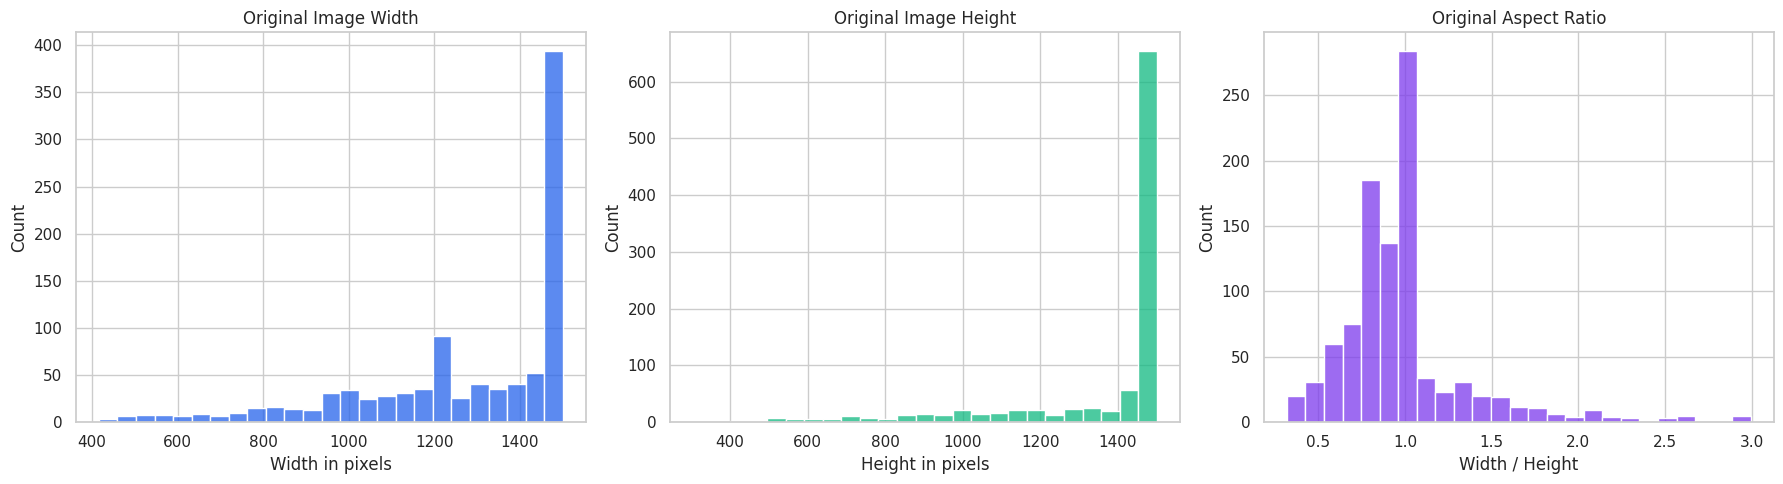

In [ ]:
# ============================================================
# Step 2.6: Image EDA
# ============================================================

sns.set_theme(
    style="whitegrid"
)

figure, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
)

sns.histplot(
    data=clean_thumbnail_index,
    x="original_width",
    bins=25,
    ax=axes[0],
    color="#2563EB",
)

axes[0].set_title(
    "Original Image Width"
)

axes[0].set_xlabel("Width in pixels")


sns.histplot(
    data=clean_thumbnail_index,
    x="original_height",
    bins=25,
    ax=axes[1],
    color="#10B981",
)

axes[1].set_title(
    "Original Image Height"
)

axes[1].set_xlabel("Height in pixels")


sns.histplot(
    data=clean_thumbnail_index,
    x="original_aspect_ratio",
    bins=25,
    ax=axes[2],
    color="#7C3AED",
)

axes[2].set_title(
    "Original Aspect Ratio"
)

axes[2].set_xlabel(
    "Width / Height"
)

plt.tight_layout()

figure.savefig(
    EDA_FIGURE_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## Cell 7 — Display a clean-image sample

This visually verifies that the preprocessing did not crop or damage the products

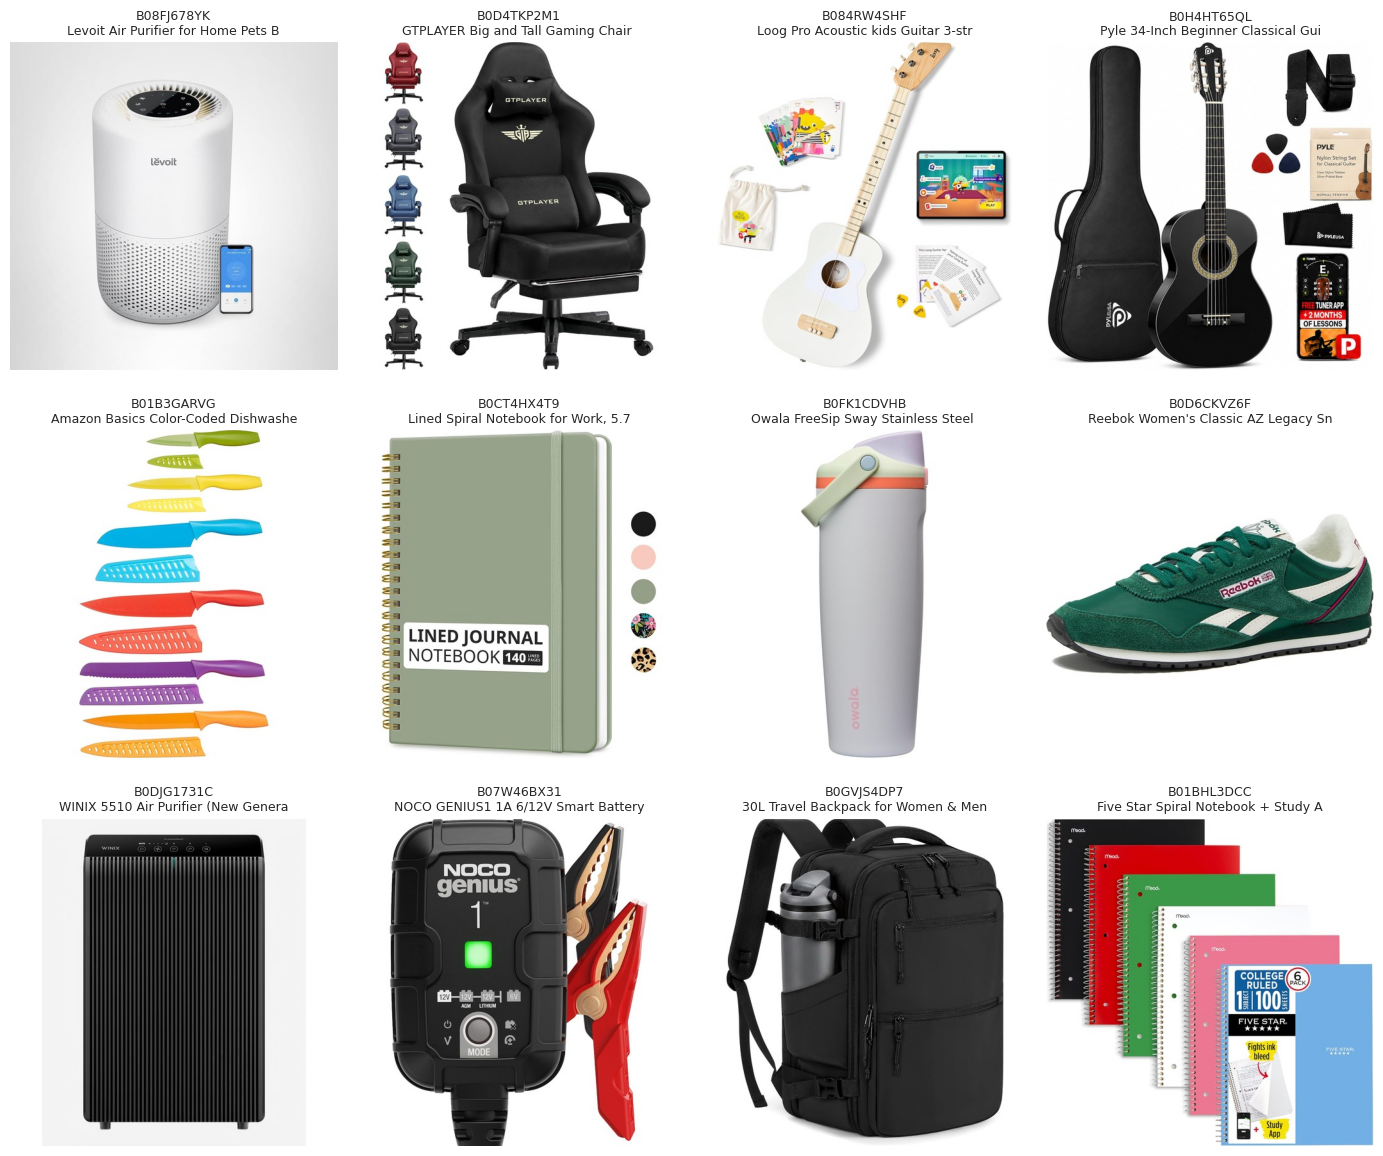

In [ ]:
# ============================================================
# Step 2.7: Clean thumbnail sample
# ============================================================

sample_rows = (
    clean_thumbnail_index[
        clean_thumbnail_index[
            "processing_status"
        ].eq("processed")
    ]
    .drop_duplicates(
        subset="processed_filename"
    )
    .sample(
        n=min(
            12,
            clean_thumbnail_index[
                "processed_filename"
            ].nunique(),
        ),
        random_state=42,
    )
    .reset_index(drop=True)
)

figure, axes = plt.subplots(
    3,
    4,
    figsize=(14, 12),
)

for axis, row in zip(
    axes.flatten(),
    sample_rows.itertuples(
        index=False
    ),
):
    image_path = (
        CLEAN_IMAGE_DIR
        / row.processed_filename
    )

    with Image.open(image_path) as image:
        axis.imshow(image)

    title = str(
        getattr(
            row,
            "title",
            row.asin,
        )
    )

    axis.set_title(
        f"{row.asin}\n{title[:35]}",
        fontsize=9,
    )

    axis.axis("off")

for axis in axes.flatten()[
    len(sample_rows):
]:
    axis.axis("off")

plt.tight_layout()
plt.show()

## Cell 8 — Save Step 2 outputs

This saves the clean index, reports and processed-image archive to Drive.

In [ ]:
# ============================================================
# Step 2.8: Save preprocessing outputs
# ============================================================

clean_thumbnail_index.to_csv(
    CLEAN_INDEX_PATH,
    index=False,
    encoding="utf-8-sig",
)

preprocessing_summary.to_csv(
    PREPROCESSING_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

quality_warnings.to_csv(
    QUALITY_WARNING_PATH,
    index=False,
    encoding="utf-8-sig",
)

LOCAL_CLEAN_ZIP_BASE = Path(
    "/content/thumbnail_clean_images"
)

local_clean_zip_path = Path(
    shutil.make_archive(
        str(LOCAL_CLEAN_ZIP_BASE),
        "zip",
        root_dir=CLEAN_IMAGE_DIR,
    )
)

shutil.copy2(
    local_clean_zip_path,
    CLEAN_IMAGE_ZIP_PATH,
)

print("Step 2 completed successfully.")
print("Clean index:", CLEAN_INDEX_PATH)
print(
    "Clean image archive:",
    CLEAN_IMAGE_ZIP_PATH,
)
print(
    "Preprocessing summary:",
    PREPROCESSING_SUMMARY_PATH,
)
print(
    "Quality warnings:",
    QUALITY_WARNING_PATH,
)
print("EDA figure:", EDA_FIGURE_PATH)

Step 2 completed successfully.
Clean index: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/thumbnail_clean_index.csv
Clean image archive: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/thumbnail_clean_images.zip
Preprocessing summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_preprocessing_summary.csv
Quality warnings: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_quality_warnings.csv
EDA figure: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_eda_summary.png


In [ ]:
# ============================================================
# Step 3.1: Install model dependencies
# ============================================================

!pip install -q "transformers>=4.45,<6.0"

## Cell 2 — Mount Drive and prepare the GPU environment

This loads the clean image index and extracts the 979 unique clean images.

In [ ]:
# ============================================================
# Step 3.2: Environment and clean-image loading
# ============================================================

from google.colab import drive
from pathlib import Path
from PIL import Image

import gc
import json
import time
import zipfile

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    ResNet50_Weights,
    resnet50,
)

from transformers import (
    AutoImageProcessor,
    AutoModel,
)


drive.mount(
    "/content/drive",
    force_remount=False,
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

CLEAN_INDEX_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "thumbnail_clean_index.csv"
)

CLEAN_IMAGE_ZIP_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "thumbnail_clean_images.zip"
)

COLAB_CLEAN_IMAGE_DIR = Path(
    "/content/thumbnail_clean_step3"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "thumbnail_grouping"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "thumbnail_grouping"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not CLEAN_INDEX_PATH.exists():
    raise FileNotFoundError(
        f"Clean index not found: {CLEAN_INDEX_PATH}"
    )

if not CLEAN_IMAGE_ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Clean image ZIP not found: "
        f"{CLEAN_IMAGE_ZIP_PATH}"
    )

COLAB_CLEAN_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

with zipfile.ZipFile(
    CLEAN_IMAGE_ZIP_PATH,
    "r",
) as zip_file:
    zip_file.extractall(
        COLAB_CLEAN_IMAGE_DIR
    )

clean_index = pd.read_csv(
    CLEAN_INDEX_PATH,
    dtype={
        "asin": str,
        "canonical_asin": str,
    },
)

unique_embedding_index = (
    clean_index[
        clean_index[
            "processing_status"
        ].eq("processed")
    ]
    .drop_duplicates(
        subset="processed_filename",
        keep="first",
    )
    .sort_values("canonical_asin")
    .reset_index(drop=True)
)

unique_embedding_index.insert(
    0,
    "embedding_row",
    range(len(unique_embedding_index)),
)

image_paths = [
    (
        COLAB_CLEAN_IMAGE_DIR
        / filename
    )
    for filename
    in unique_embedding_index[
        "processed_filename"
    ]
]

missing_files = [
    path
    for path in image_paths
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} clean images "
        "are missing after extraction."
    )

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

BATCH_SIZE = 32

print("Device:", DEVICE)
print(
    "Unique images for embedding:",
    len(image_paths),
)
print("Batch size:", BATCH_SIZE)

assert DEVICE == "cuda"
assert len(image_paths) == 979

Mounted at /content/drive
Device: cuda
Unique images for embedding: 979
Batch size: 32


## Cell 3 — Create reusable embedding helpers

In [ ]:
# ============================================================
# Step 3.3: Embedding helper functions
# ============================================================

def load_rgb_image(image_path):
    with Image.open(image_path) as image:
        return image.convert("RGB").copy()


def normalize_embeddings(embeddings):
    norms = np.linalg.norm(
        embeddings,
        axis=1,
        keepdims=True,
    )

    norms = np.clip(
        norms,
        1e-12,
        None,
    )

    return (
        embeddings / norms
    ).astype("float32")


def print_progress(
    method_name,
    completed,
    total,
):
    print(
        f"{method_name}: "
        f"{completed}/{total}"
    )

## Cell 4 — Extract ResNet50 embeddings

The final classification layer is removed, producing a 2048-dimensional visual feature vector.

In [ ]:
# ============================================================
# Step 3.4: ResNet50 visual embeddings
# ============================================================

RESNET_MODEL_NAME = (
    "torchvision/resnet50-imagenet1k"
)

resnet_weights = (
    ResNet50_Weights.DEFAULT
)

resnet_preprocess = (
    resnet_weights.transforms()
)

resnet_model = resnet50(
    weights=resnet_weights
)

resnet_model.fc = nn.Identity()

resnet_model = (
    resnet_model
    .to(DEVICE)
    .eval()
)

resnet_batches = []

resnet_start_time = time.perf_counter()

for start in range(
    0,
    len(image_paths),
    BATCH_SIZE,
):
    end = min(
        start + BATCH_SIZE,
        len(image_paths),
    )

    batch_images = torch.stack([
        resnet_preprocess(
            load_rgb_image(image_path)
        )
        for image_path
        in image_paths[start:end]
    ]).to(DEVICE)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=DEVICE == "cuda",
        ):
            batch_embeddings = (
                resnet_model(
                    batch_images
                )
            )

            batch_embeddings = (
                F.normalize(
                    batch_embeddings,
                    p=2,
                    dim=1,
                )
            )

    resnet_batches.append(
        batch_embeddings
        .float()
        .cpu()
        .numpy()
    )

    print_progress(
        "ResNet50",
        end,
        len(image_paths),
    )

resnet_extraction_seconds = (
    time.perf_counter()
    - resnet_start_time
)

resnet_embeddings = np.vstack(
    resnet_batches
).astype("float32")

resnet_embeddings = normalize_embeddings(
    resnet_embeddings
)

RESNET_EMBEDDING_PATH = (
    MODEL_DIR
    / "resnet50_embeddings_unique.npy"
)

np.save(
    RESNET_EMBEDDING_PATH,
    resnet_embeddings,
)

print(
    "ResNet50 embedding shape:",
    resnet_embeddings.shape,
)

print(
    "ResNet50 extraction time:",
    round(
        resnet_extraction_seconds,
        2,
    ),
    "seconds",
)

del resnet_model
del resnet_batches
del batch_images
del batch_embeddings

gc.collect()
torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 115MB/s]


ResNet50: 32/979
ResNet50: 64/979
ResNet50: 96/979
ResNet50: 128/979
ResNet50: 160/979
ResNet50: 192/979
ResNet50: 224/979
ResNet50: 256/979
ResNet50: 288/979
ResNet50: 320/979
ResNet50: 352/979
ResNet50: 384/979
ResNet50: 416/979
ResNet50: 448/979
ResNet50: 480/979
ResNet50: 512/979
ResNet50: 544/979
ResNet50: 576/979
ResNet50: 608/979
ResNet50: 640/979
ResNet50: 672/979
ResNet50: 704/979
ResNet50: 736/979
ResNet50: 768/979
ResNet50: 800/979
ResNet50: 832/979
ResNet50: 864/979
ResNet50: 896/979
ResNet50: 928/979
ResNet50: 960/979
ResNet50: 979/979
ResNet50 embedding shape: (979, 2048)
ResNet50 extraction time: 7.62 seconds


## Cell 5 — Extract DINOv2-Small embeddings

DINOv2-Small produces a 384-dimensional image-only visual feature vector.

In [ ]:
# ============================================================
# Step 3.5: DINOv2-Small visual embeddings
# ============================================================

DINOV2_MODEL_NAME = (
    "facebook/dinov2-small"
)

dinov2_processor = (
    AutoImageProcessor.from_pretrained(
        DINOV2_MODEL_NAME
    )
)

dinov2_model = (
    AutoModel.from_pretrained(
        DINOV2_MODEL_NAME
    )
    .to(DEVICE)
    .eval()
)

dinov2_batches = []

dinov2_start_time = time.perf_counter()

for start in range(
    0,
    len(image_paths),
    BATCH_SIZE,
):
    end = min(
        start + BATCH_SIZE,
        len(image_paths),
    )

    batch_pil_images = [
        load_rgb_image(image_path)
        for image_path
        in image_paths[start:end]
    ]

    batch_inputs = dinov2_processor(
        images=batch_pil_images,
        return_tensors="pt",
    )

    batch_inputs = {
        name: tensor.to(DEVICE)
        for name, tensor
        in batch_inputs.items()
    }

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=DEVICE == "cuda",
        ):
            model_output = dinov2_model(
                **batch_inputs
            )

            batch_embeddings = (
                model_output
                .last_hidden_state[
                    :,
                    0,
                    :
                ]
            )

            batch_embeddings = (
                F.normalize(
                    batch_embeddings,
                    p=2,
                    dim=1,
                )
            )

    dinov2_batches.append(
        batch_embeddings
        .float()
        .cpu()
        .numpy()
    )

    print_progress(
        "DINOv2",
        end,
        len(image_paths),
    )

dinov2_extraction_seconds = (
    time.perf_counter()
    - dinov2_start_time
)

dinov2_embeddings = np.vstack(
    dinov2_batches
).astype("float32")

dinov2_embeddings = normalize_embeddings(
    dinov2_embeddings
)

DINOV2_EMBEDDING_PATH = (
    MODEL_DIR
    / "dinov2_small_embeddings_unique.npy"
)

np.save(
    DINOV2_EMBEDDING_PATH,
    dinov2_embeddings,
)

print(
    "DINOv2 embedding shape:",
    dinov2_embeddings.shape,
)

print(
    "DINOv2 extraction time:",
    round(
        dinov2_extraction_seconds,
        2,
    ),
    "seconds",
)

del dinov2_model
del dinov2_batches
del batch_inputs
del batch_embeddings
del model_output

gc.collect()
torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2: 32/979
DINOv2: 64/979
DINOv2: 96/979
DINOv2: 128/979
DINOv2: 160/979
DINOv2: 192/979
DINOv2: 224/979
DINOv2: 256/979
DINOv2: 288/979
DINOv2: 320/979
DINOv2: 352/979
DINOv2: 384/979
DINOv2: 416/979
DINOv2: 448/979
DINOv2: 480/979
DINOv2: 512/979
DINOv2: 544/979
DINOv2: 576/979
DINOv2: 608/979
DINOv2: 640/979
DINOv2: 672/979
DINOv2: 704/979
DINOv2: 736/979
DINOv2: 768/979
DINOv2: 800/979
DINOv2: 832/979
DINOv2: 864/979
DINOv2: 896/979
DINOv2: 928/979
DINOv2: 960/979
DINOv2: 979/979
DINOv2 embedding shape: (979, 384)
DINOv2 extraction time: 9.64 seconds


## Cell 6 — Validate and compare embedding quality

This checks dimensions, finite values, normalization and extraction speed. It does not select the winner yet.

In [ ]:
# ============================================================
# Step 3.6: Embedding validation summary
# ============================================================

def embedding_diagnostics(
    method_name,
    embeddings,
    extraction_seconds,
):
    embedding_norms = np.linalg.norm(
        embeddings,
        axis=1,
    )

    rng = np.random.default_rng(42)

    sample_size = min(
        200,
        len(embeddings),
    )

    sample_indices = rng.choice(
        len(embeddings),
        size=sample_size,
        replace=False,
    )

    sample_embeddings = embeddings[
        sample_indices
    ]

    similarity_matrix = (
        sample_embeddings
        @ sample_embeddings.T
    )

    off_diagonal_mask = ~np.eye(
        sample_size,
        dtype=bool,
    )

    mean_pairwise_similarity = float(
        similarity_matrix[
            off_diagonal_mask
        ].mean()
    )

    return {
        "method": method_name,
        "image_count": len(embeddings),
        "embedding_dimension":
            embeddings.shape[1],
        "all_values_finite": bool(
            np.isfinite(
                embeddings
            ).all()
        ),
        "minimum_norm": float(
            embedding_norms.min()
        ),
        "maximum_norm": float(
            embedding_norms.max()
        ),
        "mean_norm": float(
            embedding_norms.mean()
        ),
        "mean_pairwise_cosine": (
            mean_pairwise_similarity
        ),
        "extraction_seconds": (
            extraction_seconds
        ),
        "images_per_second": (
            len(embeddings)
            / extraction_seconds
        ),
    }


embedding_summary = pd.DataFrame([
    embedding_diagnostics(
        method_name="ResNet50",
        embeddings=resnet_embeddings,
        extraction_seconds=(
            resnet_extraction_seconds
        ),
    ),
    embedding_diagnostics(
        method_name="DINOv2-Small",
        embeddings=dinov2_embeddings,
        extraction_seconds=(
            dinov2_extraction_seconds
        ),
    ),
])

assert embedding_summary[
    "all_values_finite"
].all()

assert (
    embedding_summary[
        "image_count"
    ]
    == 979
).all()

display(
    embedding_summary.style.format({
        "minimum_norm": "{:.6f}",
        "maximum_norm": "{:.6f}",
        "mean_norm": "{:.6f}",
        "mean_pairwise_cosine": "{:.4f}",
        "extraction_seconds": "{:.2f}",
        "images_per_second": "{:.2f}",
    })
)

,method,image_count,embedding_dimension,all_values_finite,minimum_norm,maximum_norm,mean_norm,mean_pairwise_cosine,extraction_seconds,images_per_second
0,ResNet50,979,2048,True,1.000000,1.000000,1.000000,0.2205,7.62,128.40
1,DINOv2-Small,979,384,True,1.000000,1.000000,1.000000,0.1181,9.64,101.54


## Cell 7 — Save the embedding index and metadata

The saved index preserves the exact row order of both embedding arrays.

In [ ]:
# ============================================================
# Step 3.7: Save embedding index and metadata
# ============================================================

EMBEDDING_INDEX_PATH = (
    MODEL_DIR
    / "thumbnail_embedding_index.csv"
)

EMBEDDING_SUMMARY_PATH = (
    REPORT_DIR
    / "thumbnail_embedding_summary.csv"
)

EMBEDDING_METADATA_PATH = (
    MODEL_DIR
    / "thumbnail_embedding_metadata.json"
)

embedding_index_columns = [
    column
    for column in [
        "embedding_row",
        "canonical_asin",
        "asin",
        "sha256",
        "processed_filename",
        "title",
        "image_url",
        "product_url",
    ]
    if column
    in unique_embedding_index.columns
]

unique_embedding_index[
    embedding_index_columns
].to_csv(
    EMBEDDING_INDEX_PATH,
    index=False,
    encoding="utf-8-sig",
)

embedding_summary.to_csv(
    EMBEDDING_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

embedding_metadata = {
    "unique_image_count": int(
        len(unique_embedding_index)
    ),
    "product_count": int(
        len(clean_index)
    ),
    "resnet50": {
        "model_name": RESNET_MODEL_NAME,
        "embedding_dimension": int(
            resnet_embeddings.shape[1]
        ),
        "embedding_file": (
            RESNET_EMBEDDING_PATH.name
        ),
    },
    "dinov2_small": {
        "model_name": DINOV2_MODEL_NAME,
        "embedding_dimension": int(
            dinov2_embeddings.shape[1]
        ),
        "embedding_file": (
            DINOV2_EMBEDDING_PATH.name
        ),
    },
    "normalized": True,
    "category_used": False,
    "keyword_used": False,
    "title_used": False,
    "brand_used": False,
    "description_used": False,
}

with open(
    EMBEDDING_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        embedding_metadata,
        file,
        indent=2,
    )

print("Step 3 completed successfully.")
print(
    "ResNet50 embeddings:",
    RESNET_EMBEDDING_PATH,
)
print(
    "DINOv2 embeddings:",
    DINOV2_EMBEDDING_PATH,
)
print(
    "Embedding index:",
    EMBEDDING_INDEX_PATH,
)
print(
    "Embedding summary:",
    EMBEDDING_SUMMARY_PATH,
)
print(
    "Metadata:",
    EMBEDDING_METADATA_PATH,
)

Step 3 completed successfully.
ResNet50 embeddings: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/resnet50_embeddings_unique.npy
DINOv2 embeddings: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/dinov2_small_embeddings_unique.npy
Embedding index: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_embedding_index.csv
Embedding summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_embedding_summary.csv
Metadata: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_embedding_metadata.json


## Step 4 — PCA and clustering preparation

This step will:

Reduce redundant embedding dimensions.
Preserve 95% of the variance.
Normalize the reduced embeddings.
Save separate PCA models for ResNet50 and DINOv2.
Prepare both feature sets for K-Means.

PCA and K-Means run on CPU, so keeping the current Colab session is fine.

## Cell 1 — Load dependencies and saved embeddings

This cell works even if the Colab runtime was restarted.

In [ ]:
# ============================================================
# Step 4.1: PCA setup and embedding loading
# ============================================================

import joblib

from sklearn.decomposition import PCA


RESNET_EMBEDDING_PATH = (
    MODEL_DIR
    / "resnet50_embeddings_unique.npy"
)

DINOV2_EMBEDDING_PATH = (
    MODEL_DIR
    / "dinov2_small_embeddings_unique.npy"
)

if "resnet_embeddings" not in globals():
    resnet_embeddings = np.load(
        RESNET_EMBEDDING_PATH
    ).astype("float32")

if "dinov2_embeddings" not in globals():
    dinov2_embeddings = np.load(
        DINOV2_EMBEDDING_PATH
    ).astype("float32")

print(
    "ResNet50 embeddings:",
    resnet_embeddings.shape,
)

print(
    "DINOv2 embeddings:",
    dinov2_embeddings.shape,
)

assert resnet_embeddings.shape == (
    979,
    2048,
)

assert dinov2_embeddings.shape == (
    979,
    384,
)

ResNet50 embeddings: (979, 2048)
DINOv2 embeddings: (979, 384)


## Cell 2 — Create the PCA preparation function

A variance threshold is better than manually choosing an arbitrary feature dimension.

In [ ]:
# ============================================================
# Step 4.2: PCA preparation function
# ============================================================

PCA_VARIANCE_THRESHOLD = 0.95


def prepare_embeddings_with_pca(
    method_name,
    embeddings,
):
    start_time = time.perf_counter()

    pca_model = PCA(
        n_components=(
            PCA_VARIANCE_THRESHOLD
        ),
        svd_solver="full",
    )

    reduced_embeddings = (
        pca_model.fit_transform(
            embeddings
        )
    )

    reduced_embeddings = (
        normalize_embeddings(
            reduced_embeddings
        )
    )

    elapsed_seconds = (
        time.perf_counter()
        - start_time
    )

    explained_variance = float(
        pca_model
        .explained_variance_ratio_
        .sum()
    )

    embedding_norms = np.linalg.norm(
        reduced_embeddings,
        axis=1,
    )

    result_summary = {
        "method": method_name,
        "image_count": len(embeddings),
        "original_dimension":
            embeddings.shape[1],
        "reduced_dimension":
            reduced_embeddings.shape[1],
        "explained_variance":
            explained_variance,
        "dimension_reduction_percentage": (
            1
            - (
                reduced_embeddings.shape[1]
                / embeddings.shape[1]
            )
        )
        * 100,
        "pca_seconds": elapsed_seconds,
        "minimum_norm": float(
            embedding_norms.min()
        ),
        "maximum_norm": float(
            embedding_norms.max()
        ),
        "all_values_finite": bool(
            np.isfinite(
                reduced_embeddings
            ).all()
        ),
    }

    return (
        pca_model,
        reduced_embeddings,
        result_summary,
    )

## Cell 3 — Apply PCA to ResNet50

In [ ]:
# ============================================================
# Step 4.3: Prepare ResNet50 embeddings
# ============================================================

(
    resnet_pca,
    resnet_reduced_embeddings,
    resnet_pca_summary,
) = prepare_embeddings_with_pca(
    method_name="ResNet50",
    embeddings=resnet_embeddings,
)

print(
    "ResNet50 reduced shape:",
    resnet_reduced_embeddings.shape,
)

print(
    "Explained variance:",
    round(
        resnet_pca_summary[
            "explained_variance"
        ],
        4,
    ),
)

ResNet50 reduced shape: (979, 331)
Explained variance: 0.9501


## Cell 4 — Apply PCA to DINOv2

In [ ]:
# ============================================================
# Step 4.4: Prepare DINOv2 embeddings
# ============================================================

(
    dinov2_pca,
    dinov2_reduced_embeddings,
    dinov2_pca_summary,
) = prepare_embeddings_with_pca(
    method_name="DINOv2-Small",
    embeddings=dinov2_embeddings,
)

print(
    "DINOv2 reduced shape:",
    dinov2_reduced_embeddings.shape,
)

print(
    "Explained variance:",
    round(
        dinov2_pca_summary[
            "explained_variance"
        ],
        4,
    ),
)

DINOv2 reduced shape: (979, 171)
Explained variance: 0.9501


## Cell 5 — Compare the PCA results

In [ ]:
# ============================================================
# Step 4.5: PCA comparison
# ============================================================

pca_summary = pd.DataFrame([
    resnet_pca_summary,
    dinov2_pca_summary,
])

assert pca_summary[
    "all_values_finite"
].all()

assert (
    pca_summary[
        "explained_variance"
    ]
    >= 0.95
).all()

display(
    pca_summary.style.format({
        "explained_variance": "{:.4f}",
        "dimension_reduction_percentage":
            "{:.2f}%",
        "pca_seconds": "{:.2f}",
        "minimum_norm": "{:.6f}",
        "maximum_norm": "{:.6f}",
    })
)

,method,image_count,original_dimension,reduced_dimension,explained_variance,dimension_reduction_percentage,pca_seconds,minimum_norm,maximum_norm,all_values_finite
0,ResNet50,979,2048,331,0.9501,83.84%,1.42,0.999999,1.000001,True
1,DINOv2-Small,979,384,171,0.9501,55.47%,0.05,0.999999,1.000001,True


## Cell 6 — Save PCA artifacts

In [ ]:
# ============================================================
# Step 4.6: Save PCA artifacts
# ============================================================

RESNET_PCA_PATH = (
    MODEL_DIR
    / "resnet50_pca.joblib"
)

DINOV2_PCA_PATH = (
    MODEL_DIR
    / "dinov2_small_pca.joblib"
)

RESNET_REDUCED_PATH = (
    MODEL_DIR
    / "resnet50_embeddings_pca.npy"
)

DINOV2_REDUCED_PATH = (
    MODEL_DIR
    / "dinov2_small_embeddings_pca.npy"
)

PCA_SUMMARY_PATH = (
    REPORT_DIR
    / "thumbnail_pca_summary.csv"
)

joblib.dump(
    resnet_pca,
    RESNET_PCA_PATH,
)

joblib.dump(
    dinov2_pca,
    DINOV2_PCA_PATH,
)

np.save(
    RESNET_REDUCED_PATH,
    resnet_reduced_embeddings,
)

np.save(
    DINOV2_REDUCED_PATH,
    dinov2_reduced_embeddings,
)

pca_summary.to_csv(
    PCA_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Step 4 completed successfully.")
print("ResNet50 PCA:", RESNET_PCA_PATH)
print("DINOv2 PCA:", DINOV2_PCA_PATH)
print(
    "ResNet50 reduced embeddings:",
    RESNET_REDUCED_PATH,
)
print(
    "DINOv2 reduced embeddings:",
    DINOV2_REDUCED_PATH,
)
print("PCA summary:", PCA_SUMMARY_PATH)

Step 4 completed successfully.
ResNet50 PCA: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/resnet50_pca.joblib
DINOv2 PCA: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/dinov2_small_pca.joblib
ResNet50 reduced embeddings: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/resnet50_embeddings_pca.npy
DINOv2 reduced embeddings: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/dinov2_small_embeddings_pca.npy
PCA summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_pca_summary.csv


## Step 5 — K-Means with Elbow and Silhouette

This step will:

Test K = 2 through 30.
Calculate inertia for the Elbow Method.
Calculate cosine Silhouette Score.
Detect an elbow automatically.
Select the highest silhouette around the elbow.
Compare ResNet50 and DINOv2.
Fit the final K-Means model.

## Cell 1 — Configure K-Means evaluation

In [ ]:
# ============================================================
# Step 5.1: K-Means evaluation setup
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


K_VALUES = list(
    range(2, 31)
)

KMEANS_RANDOM_STATE = 42
KMEANS_N_INIT = 10
KMEANS_MAX_ITER = 300

embedding_methods = {
    "ResNet50": (
        resnet_reduced_embeddings
    ),
    "DINOv2-Small": (
        dinov2_reduced_embeddings
    ),
}

print("K values:", K_VALUES)
print(
    "Number of images:",
    len(resnet_reduced_embeddings),
)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
Number of images: 979


## Cell 2 — Evaluate every K-Means configuration

Only inertia and Silhouette Score are calculated.

In [ ]:
# ============================================================
# Step 5.2: Evaluate K-Means configurations
# ============================================================

kmeans_evaluation_rows = []

for method_name, embeddings in (
    embedding_methods.items()
):
    print(
        "\nEvaluating:",
        method_name,
    )

    for cluster_count in K_VALUES:
        start_time = (
            time.perf_counter()
        )

        candidate_model = KMeans(
            n_clusters=cluster_count,
            init="k-means++",
            n_init=KMEANS_N_INIT,
            max_iter=KMEANS_MAX_ITER,
            random_state=(
                KMEANS_RANDOM_STATE
            ),
            algorithm="lloyd",
        )

        cluster_labels = (
            candidate_model.fit_predict(
                embeddings
            )
        )

        inertia = float(
            candidate_model.inertia_
        )

        silhouette = float(
            silhouette_score(
                embeddings,
                cluster_labels,
                metric="cosine",
            )
        )

        elapsed_seconds = (
            time.perf_counter()
            - start_time
        )

        kmeans_evaluation_rows.append({
            "method": method_name,
            "k": cluster_count,
            "inertia": inertia,
            "silhouette_score":
                silhouette,
            "fit_seconds":
                elapsed_seconds,
        })

        print(
            f"K={cluster_count:2d} | "
            f"Inertia={inertia:.4f} | "
            f"Silhouette={silhouette:.4f}"
        )


kmeans_evaluation = pd.DataFrame(
    kmeans_evaluation_rows
)

print(
    "\nConfigurations evaluated:",
    len(kmeans_evaluation),
)

assert len(kmeans_evaluation) == (
    len(K_VALUES)
    * len(embedding_methods)
)


Evaluating: ResNet50
K= 2 | Inertia=924.1010 | Silhouette=0.1034
K= 3 | Inertia=883.2375 | Silhouette=0.1150
K= 4 | Inertia=845.4166 | Silhouette=0.1352
K= 5 | Inertia=811.6669 | Silhouette=0.1600
K= 6 | Inertia=783.2167 | Silhouette=0.1754
K= 7 | Inertia=750.8364 | Silhouette=0.2029
K= 8 | Inertia=724.3589 | Silhouette=0.2248
K= 9 | Inertia=711.0206 | Silhouette=0.2200
K=10 | Inertia=680.5056 | Silhouette=0.2472
K=11 | Inertia=660.9973 | Silhouette=0.2638
K=12 | Inertia=643.2269 | Silhouette=0.2721
K=13 | Inertia=622.5622 | Silhouette=0.2892
K=14 | Inertia=609.1409 | Silhouette=0.3025
K=15 | Inertia=594.6855 | Silhouette=0.3086
K=16 | Inertia=582.6572 | Silhouette=0.3141
K=17 | Inertia=576.4775 | Silhouette=0.3183
K=18 | Inertia=561.4503 | Silhouette=0.3241
K=19 | Inertia=553.6450 | Silhouette=0.3245
K=20 | Inertia=544.4684 | Silhouette=0.3284
K=21 | Inertia=533.0119 | Silhouette=0.3449
K=22 | Inertia=524.5621 | Silhouette=0.3417
K=23 | Inertia=522.1893 | Silhouette=0.3425
K=24 | Ine

## Cell 3 — Detect the elbow automatically

This uses the maximum distance between the normalized inertia curve and the line connecting its first and final points.

In [ ]:
# ============================================================
# Step 5.3: Automatic elbow detection
# ============================================================

def detect_elbow(
    k_values,
    inertia_values,
):
    x_values = np.asarray(
        k_values,
        dtype="float64",
    )

    y_values = np.asarray(
        inertia_values,
        dtype="float64",
    )

    normalized_x = (
        x_values - x_values.min()
    ) / (
        x_values.max()
        - x_values.min()
    )

    normalized_y = (
        y_values - y_values.min()
    ) / (
        y_values.max()
        - y_values.min()
    )

    start_point = np.array([
        normalized_x[0],
        normalized_y[0],
    ])

    end_point = np.array([
        normalized_x[-1],
        normalized_y[-1],
    ])

    line_vector = (
        end_point - start_point
    )

    line_length = np.linalg.norm(
        line_vector
    )

    distances = []

    for x_value, y_value in zip(
        normalized_x,
        normalized_y,
    ):
        point = np.array([
            x_value,
            y_value,
        ])

        distance = abs(
            np.cross(
                line_vector,
                point - start_point,
            )
        ) / line_length

        distances.append(distance)

    elbow_position = int(
        np.argmax(distances)
    )

    return int(
        x_values[elbow_position]
    )

## Cell 4 — Select K using Elbow and Silhouette

The final K is the highest-silhouette configuration within ±2 of the detected elbow.

In [ ]:
# ============================================================
# Step 5.4: Select K using highest Silhouette Score
# ============================================================

method_selection_rows = []

for method_name in embedding_methods:

    method_results = (
        kmeans_evaluation[
            kmeans_evaluation[
                "method"
            ].eq(method_name)
        ]
        .sort_values("k")
        .reset_index(drop=True)
    )

    # Elbow remains an informative reference.
    elbow_k = detect_elbow(
        method_results["k"],
        method_results["inertia"],
    )

    # Final K is selected using the highest
    # cosine Silhouette Score.
    selected_row = (
        method_results
        .sort_values(
            [
                "silhouette_score",
                "k",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .iloc[0]
    )

    selected_k = int(
        selected_row["k"]
    )

    method_selection_rows.append({
        "method": method_name,
        "elbow_k": elbow_k,
        "selected_k": selected_k,
        "selected_inertia": float(
            selected_row["inertia"]
        ),
        "selected_silhouette": float(
            selected_row[
                "silhouette_score"
            ]
        ),
        "global_best_silhouette_k":
            selected_k,
        "global_best_silhouette":
            float(
                selected_row[
                    "silhouette_score"
                ]
            ),
        "selection_rule": (
            "Highest cosine Silhouette Score; "
            "Elbow retained as reference"
        ),
    })


method_selection = (
    pd.DataFrame(
        method_selection_rows
    )
    .sort_values(
        "selected_silhouette",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    method_selection.style.format({
        "selected_inertia": "{:.4f}",
        "selected_silhouette": "{:.4f}",
        "global_best_silhouette":
            "{:.4f}",
    })
)

/tmp/ipykernel_6005/4010035595.py:63: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  np.cross(


,method,elbow_k,selected_k,selected_inertia,selected_silhouette,global_best_silhouette_k,global_best_silhouette,selection_rule
0,DINOv2-Small,13,26,451.6918,0.4229,26,0.4229,Highest cosine Silhouette Score; Elbow retained as reference
1,ResNet50,13,28,488.8313,0.3590,28,0.3590,Highest cosine Silhouette Score; Elbow retained as reference


## Cell 5 — Visualize Elbow and Silhouette results

The graphs must be inspected before accepting the automatic result.

In [ ]:
import matplotlib.pyplot as plt

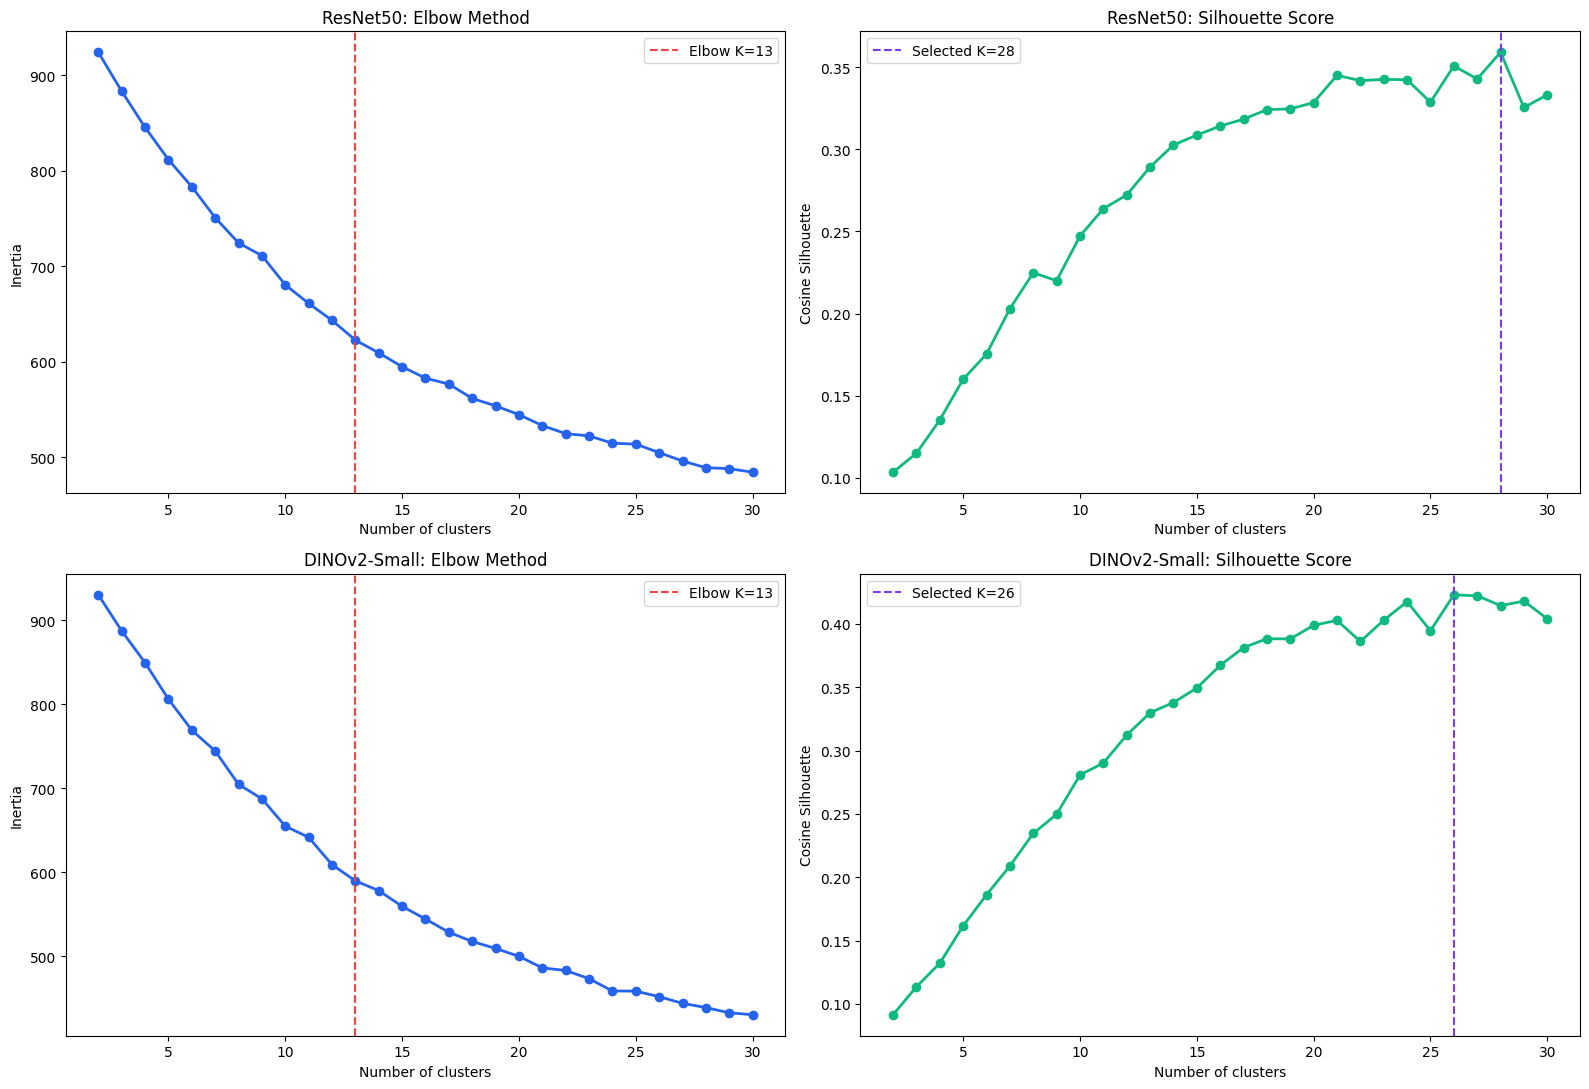

In [ ]:
# ============================================================
# Step 5.5: Elbow and Silhouette visualizations
# ============================================================

figure, axes = plt.subplots(
    len(embedding_methods),
    2,
    figsize=(16, 11),
)

for row_number, method_name in enumerate(
    embedding_methods
):
    method_results = (
        kmeans_evaluation[
            kmeans_evaluation[
                "method"
            ].eq(method_name)
        ]
        .sort_values("k")
    )

    selection_row = (
        method_selection[
            method_selection[
                "method"
            ].eq(method_name)
        ]
        .iloc[0]
    )

    elbow_k = int(
        selection_row["elbow_k"]
    )

    selected_k = int(
        selection_row["selected_k"]
    )

    axes[row_number, 0].plot(
        method_results["k"],
        method_results["inertia"],
        marker="o",
        linewidth=2,
        color="#2563EB",
    )

    axes[row_number, 0].axvline(
        elbow_k,
        color="#EF4444",
        linestyle="--",
        label=f"Elbow K={elbow_k}",
    )

    axes[row_number, 0].set_title(
        f"{method_name}: Elbow Method"
    )

    axes[row_number, 0].set_xlabel(
        "Number of clusters"
    )

    axes[row_number, 0].set_ylabel(
        "Inertia"
    )

    axes[row_number, 0].legend()


    axes[row_number, 1].plot(
        method_results["k"],
        method_results[
            "silhouette_score"
        ],
        marker="o",
        linewidth=2,
        color="#10B981",
    )

    axes[row_number, 1].axvline(
        selected_k,
        color="#7C3AED",
        linestyle="--",
        label=(
            f"Selected K={selected_k}"
        ),
    )

    axes[row_number, 1].set_title(
        f"{method_name}: Silhouette Score"
    )

    axes[row_number, 1].set_xlabel(
        "Number of clusters"
    )

    axes[row_number, 1].set_ylabel(
        "Cosine Silhouette"
    )

    axes[row_number, 1].legend()


plt.tight_layout()

KMEANS_FIGURE_PATH = (
    REPORT_DIR
    / "kmeans_elbow_silhouette.png"
)

figure.savefig(
    KMEANS_FIGURE_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## Cell 6 — Select the final feature method

The method with the stronger selected Silhouette Score wins

In [ ]:
# ============================================================
# Step 5.6: Select final visual feature method
# ============================================================

final_selection_row = (
    method_selection.iloc[0]
)

selected_feature_method = str(
    final_selection_row["method"]
)

selected_cluster_count = int(
    final_selection_row["selected_k"]
)

selected_silhouette = float(
    final_selection_row[
        "selected_silhouette"
    ]
)

selected_embeddings = (
    embedding_methods[
        selected_feature_method
    ]
)

print(
    "Selected feature method:",
    selected_feature_method,
)

print(
    "Selected number of clusters:",
    selected_cluster_count,
)

print(
    "Selected Silhouette Score:",
    round(
        selected_silhouette,
        4,
    ),
)

Selected feature method: DINOv2-Small
Selected number of clusters: 26
Selected Silhouette Score: 0.4229


## Cell 7 — Fit the final K-Means model

In [ ]:
# ============================================================
# Step 5.7: Fit final K-Means model
# ============================================================

final_kmeans_model = KMeans(
    n_clusters=selected_cluster_count,
    init="k-means++",
    n_init=KMEANS_N_INIT,
    max_iter=KMEANS_MAX_ITER,
    random_state=KMEANS_RANDOM_STATE,
    algorithm="lloyd",
)

final_unique_labels = (
    final_kmeans_model.fit_predict(
        selected_embeddings
    )
)

unique_cluster_distribution = (
    pd.Series(
        final_unique_labels,
        name="cluster_id",
    )
    .value_counts()
    .sort_index()
    .rename("image_count")
    .reset_index()
)

assert len(final_unique_labels) == 979

assert (
    unique_cluster_distribution[
        "image_count"
    ].sum()
    == 979
)

display(unique_cluster_distribution)

print(
    "Final K-Means fitted successfully."
)

,cluster_id,image_count
0,0,24
1,1,15
2,2,57
3,3,54
4,4,39
5,5,54
6,6,18
7,7,31
8,8,60
9,9,52


Final K-Means fitted successfully.


# Cell 8 — Save Step 5 reports

The final model itself will be saved in Step 6 after cluster interpretation and full ASIN mapping.

In [ ]:
# ============================================================
# Step 5.8: Save K-Means evaluation reports
# ============================================================

KMEANS_EVALUATION_PATH = (
    REPORT_DIR
    / "kmeans_cluster_selection.csv"
)

METHOD_SELECTION_PATH = (
    REPORT_DIR
    / "thumbnail_feature_selection.csv"
)

kmeans_evaluation.to_csv(
    KMEANS_EVALUATION_PATH,
    index=False,
    encoding="utf-8-sig",
)

method_selection.to_csv(
    METHOD_SELECTION_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Step 5 completed successfully.")
print(
    "K-Means evaluation:",
    KMEANS_EVALUATION_PATH,
)
print(
    "Method selection:",
    METHOD_SELECTION_PATH,
)
print(
    "Evaluation figure:",
    KMEANS_FIGURE_PATH,
)

Step 5 completed successfully.
K-Means evaluation: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/kmeans_cluster_selection.csv
Method selection: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_feature_selection.csv
Evaluation figure: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/kmeans_elbow_silhouette.png


## Step 6 — Cluster interpretation and final artifacts



## Step 6A — Train the final KMeans model

In [ ]:
# ============================================================
# Step 6A: Train the final selected KMeans model
# ============================================================

import json
import zipfile
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from PIL import Image
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    normalized_mutual_info_score,
    silhouette_samples,
)
from sklearn.preprocessing import normalize


SELECTED_METHOD = "DINOv2-Small"
FINAL_K = 26
RANDOM_STATE = 42

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "thumbnail_grouping"
)

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "thumbnail_grouping"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# embedding_methods was created during Steps 4–5
if "embedding_methods" not in globals():
    raise NameError(
        "embedding_methods is unavailable. "
        "Rerun the Step 4 and Step 5 cells first."
    )

if SELECTED_METHOD not in embedding_methods:
    raise KeyError(
        f"{SELECTED_METHOD} was not found in embedding_methods."
    )

selected_embeddings = np.asarray(
    embedding_methods[SELECTED_METHOD],
    dtype=np.float32,
)

if selected_embeddings.shape[0] != 979:
    raise ValueError(
        "Expected 979 unique-image embeddings, "
        f"but found {selected_embeddings.shape[0]}."
    )

if not np.isfinite(selected_embeddings).all():
    raise ValueError(
        "The selected embedding matrix contains invalid values."
    )


final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=RANDOM_STATE,
    n_init=10,
    max_iter=300,
)

final_unique_labels = final_kmeans.fit_predict(
    selected_embeddings
)

unique_silhouette_values = silhouette_samples(
    selected_embeddings,
    final_unique_labels,
    metric="cosine",
)

final_silhouette = float(
    unique_silhouette_values.mean()
)

cluster_sizes = (
    pd.Series(
        final_unique_labels,
        name="cluster_id",
    )
    .value_counts()
    .sort_index()
    .rename("image_count")
    .reset_index()
)

print("Final method:", SELECTED_METHOD)
print("Final K:", FINAL_K)
print("Unique images:", len(selected_embeddings))
print("Final cosine silhouette:", round(final_silhouette, 4))
print("Smallest cluster:", cluster_sizes["image_count"].min())
print("Largest cluster:", cluster_sizes["image_count"].max())
print("Average cluster size:", round(cluster_sizes["image_count"].mean(), 2))
print("Clusters below 5 images:",
      int((cluster_sizes["image_count"] < 5).sum()))

display(cluster_sizes)

Final method: DINOv2-Small
Final K: 26
Unique images: 979
Final cosine silhouette: 0.4229
Smallest cluster: 9
Largest cluster: 60
Average cluster size: 37.65
Clusters below 5 images: 0


,cluster_id,image_count
0,0,24
1,1,15
2,2,57
3,3,54
4,4,39
5,5,54
6,6,18
7,7,31
8,8,60
9,9,52


## Step 6B — Create assignments for all 981 products

This maps the 979 unique images back to all 981 ASINs. The two exact duplicate images will receive the same visual group as their canonical images.

In [ ]:
# ============================================================
# Step 6B: Map unique-image clusters to all products
# ============================================================

EMBEDDING_INDEX_PATH = (
    MODEL_DIR
    / "thumbnail_embedding_index.csv"
)

CLEAN_INDEX_PATH = (
    PROCESSED_DIR
    / "thumbnail_clean_index.csv"
)


if "embedding_index" not in globals():
    if not EMBEDDING_INDEX_PATH.exists():
        raise FileNotFoundError(
            f"Embedding index not found: {EMBEDDING_INDEX_PATH}"
        )

    embedding_index = pd.read_csv(
        EMBEDDING_INDEX_PATH,
        dtype={"asin": str, "canonical_asin": str},
    )


if len(embedding_index) != len(selected_embeddings):
    raise ValueError(
        "Embedding-index order does not match the embedding matrix. "
        f"Index rows: {len(embedding_index)}, "
        f"embedding rows: {len(selected_embeddings)}"
    )


unique_assignments = embedding_index.copy()

if "canonical_asin" in unique_assignments.columns:
    unique_assignments["canonical_asin"] = (
        unique_assignments["canonical_asin"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
    )
elif "asin" in unique_assignments.columns:
    unique_assignments["canonical_asin"] = (
        unique_assignments["asin"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
    )
else:
    raise ValueError(
        "The embedding index must contain either "
        "'asin' or 'canonical_asin'."
    )


unique_assignments["cluster_id"] = final_unique_labels
unique_assignments["cluster_name"] = (
    unique_assignments["cluster_id"]
    .add(1)
    .map(lambda value: f"Visual Group {value:02d}")
)

unique_assignments["silhouette_value"] = (
    unique_silhouette_values
)


# Cosine similarity with assigned centroid
normalized_centroids = normalize(
    final_kmeans.cluster_centers_
).astype(np.float32)

assigned_centroids = normalized_centroids[
    final_unique_labels
]

unique_assignments["centroid_similarity"] = np.sum(
    selected_embeddings * assigned_centroids,
    axis=1,
)


# Load the complete 981-product clean-image index
clean_index = pd.read_csv(
    CLEAN_INDEX_PATH,
    dtype={"asin": str, "canonical_asin": str},
)

clean_index["asin"] = (
    clean_index["asin"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)


# Create canonical ASIN if the column is unavailable
if "canonical_asin" not in clean_index.columns:
    if "sha256" not in clean_index.columns:
        raise ValueError(
            "thumbnail_clean_index.csv needs either "
            "'canonical_asin' or 'sha256'."
        )

    clean_index["canonical_asin"] = (
        clean_index
        .groupby("sha256")["asin"]
        .transform("first")
    )
else:
    clean_index["canonical_asin"] = (
        clean_index["canonical_asin"]
        .fillna(clean_index["asin"])
        .astype(str)
        .str.strip()
        .str.upper()
    )


unique_lookup = (
    unique_assignments[
        [
            "canonical_asin",
            "cluster_id",
            "cluster_name",
            "silhouette_value",
            "centroid_similarity",
        ]
    ]
    .drop_duplicates("canonical_asin")
)


full_assignments = clean_index.merge(
    unique_lookup,
    on="canonical_asin",
    how="left",
    validate="many_to_one",
)


if full_assignments["cluster_id"].isna().any():
    missing = full_assignments.loc[
        full_assignments["cluster_id"].isna(),
        ["asin", "canonical_asin"],
    ]

    raise ValueError(
        "Some products could not be assigned to a cluster:\n"
        + missing.head().to_string(index=False)
    )


full_assignments["cluster_id"] = (
    full_assignments["cluster_id"].astype(int)
)

if len(full_assignments) != 981:
    raise ValueError(
        f"Expected 981 product assignments, "
        f"but found {len(full_assignments)}."
    )


# Add product metadata for interpretation only
if "product_index" not in globals():
    product_candidates = [
        PROCESSED_DIR / "products_recommendation_clean.csv",
        PROJECT_ROOT / "data" / "raw" / "amazon_products.csv",
        PROJECT_ROOT / "data" / "amazon_products.csv",
    ]

    product_path = next(
        (path for path in product_candidates if path.exists()),
        None,
    )

    if product_path is None:
        raise FileNotFoundError(
            "The product dataset could not be found."
        )

    product_index = pd.read_csv(
        product_path,
        dtype={"asin": str},
    )

    product_index = product_index.drop_duplicates(
        "asin",
        keep="first",
    )


product_index["asin"] = (
    product_index["asin"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

metadata_columns = [
    column
    for column in [
        "asin",
        "title",
        "brand",
        "keyword_list",
        "image_url",
        "product_url",
    ]
    if column in product_index.columns
]

full_assignments = full_assignments.merge(
    product_index[metadata_columns],
    on="asin",
    how="left",
    validate="one_to_one",
)

print("Unique image assignments:", len(unique_assignments))
print("Complete product assignments:", len(full_assignments))
print("Missing assignments:",
      int(full_assignments["cluster_id"].isna().sum()))

display(
    full_assignments[
        [
            column
            for column in [
                "asin",
                "canonical_asin",
                "title",
                "cluster_name",
                "centroid_similarity",
                "silhouette_value",
            ]
            if column in full_assignments.columns
        ]
    ].head()
)

Unique image assignments: 979
Complete product assignments: 981
Missing assignments: 0


,asin,canonical_asin,cluster_name,centroid_similarity,silhouette_value
0,8883707168,8883707168,Visual Group 11,0.691082,0.323448
1,B00005IBX9,B00005IBX9,Visual Group 19,0.778748,0.330108
2,B00006IV0Q,B00006IV0Q,Visual Group 14,0.465936,0.047499
3,B00009J580,B00009J580,Visual Group 05,0.877532,0.686224
4,B0006ZAU22,B0006ZAU22,Visual Group 05,0.852741,0.651981


## Step 6C — Interpret the visual groups

Important: titles and keywords are used only after clustering to explain and audit the groups. They do not change any cluster assignment.

In [ ]:
# ============================================================
# Step 6C: Evidence-based cluster interpretation
# ============================================================

# Select five images nearest each cluster centroid
representatives = (
    unique_assignments
    .sort_values(
        ["cluster_id", "centroid_similarity"],
        ascending=[True, False],
    )
    .groupby("cluster_id", group_keys=False)
    .head(5)
    .copy()
)

representatives["representative_rank"] = (
    representatives
    .groupby("cluster_id")
    .cumcount()
    .add(1)
)

representatives = representatives.merge(
    product_index[
        [
            column
            for column in [
                "asin",
                "title",
                "brand",
                "keyword_list",
            ]
            if column in product_index.columns
        ]
    ],
    left_on="canonical_asin",
    right_on="asin",
    how="left",
    suffixes=("", "_product"),
)


# ------------------------------------------------------------
# Common title terms — interpretation only
# ------------------------------------------------------------

if "title" in full_assignments.columns:
    cluster_documents = (
        full_assignments
        .assign(
            title=full_assignments["title"]
            .fillna("")
            .astype(str)
        )
        .groupby("cluster_id")["title"]
        .apply(" ".join)
        .reindex(range(FINAL_K), fill_value="")
    )

    title_vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=3000,
        min_df=1,
    )

    title_matrix = title_vectorizer.fit_transform(
        cluster_documents
    )

    title_features = np.asarray(
        title_vectorizer.get_feature_names_out()
    )

    cluster_title_terms = {}

    for row_number, cluster_id in enumerate(
        cluster_documents.index
    ):
        scores = title_matrix[row_number].toarray().ravel()
        best_indices = scores.argsort()[::-1][:5]

        terms = [
            title_features[index]
            for index in best_indices
            if scores[index] > 0
        ]

        cluster_title_terms[int(cluster_id)] = ", ".join(terms)
else:
    cluster_title_terms = {
        cluster_id: ""
        for cluster_id in range(FINAL_K)
    }


# ------------------------------------------------------------
# Keyword alignment audit — not a clustering input
# ------------------------------------------------------------

keyword_audit = full_assignments[
    ["asin", "cluster_id", "cluster_name"]
].copy()

if "keyword_list" in full_assignments.columns:
    keyword_audit["primary_keyword"] = (
        full_assignments["keyword_list"]
        .fillna("Unknown")
        .astype(str)
        .str.split("|", regex=False)
        .str[0]
        .str.strip()
        .replace("", "Unknown")
    )
else:
    keyword_audit["primary_keyword"] = "Unavailable"


keyword_counts = (
    keyword_audit
    .groupby(["cluster_id", "primary_keyword"])
    .size()
    .rename("product_count")
    .reset_index()
)

dominant_keyword_rows = (
    keyword_counts
    .sort_values(
        ["cluster_id", "product_count"],
        ascending=[True, False],
    )
    .groupby("cluster_id", as_index=False)
    .first()
    .rename(
        columns={
            "primary_keyword": "dominant_keyword_audit",
            "product_count": "dominant_keyword_count",
        }
    )
)

keyword_summary = (
    keyword_audit
    .groupby("cluster_id")
    .agg(
        unique_keyword_count=(
            "primary_keyword",
            "nunique",
        ),
        audited_product_count=(
            "asin",
            "count",
        ),
    )
    .reset_index()
    .merge(
        dominant_keyword_rows,
        on="cluster_id",
        how="left",
    )
)

keyword_summary["dominant_keyword_share"] = (
    keyword_summary["dominant_keyword_count"]
    / keyword_summary["audited_product_count"]
)


keyword_nmi = float(
    normalized_mutual_info_score(
        keyword_audit["primary_keyword"],
        keyword_audit["cluster_id"],
    )
)


# ------------------------------------------------------------
# Cluster-quality evidence
# ------------------------------------------------------------

cluster_quality = (
    unique_assignments
    .groupby("cluster_id")
    .agg(
        unique_image_count=("canonical_asin", "count"),
        average_silhouette=("silhouette_value", "mean"),
        minimum_silhouette=("silhouette_value", "min"),
        negative_silhouette_count=(
            "silhouette_value",
            lambda values: int((values < 0).sum()),
        ),
        average_centroid_similarity=(
            "centroid_similarity",
            "mean",
        ),
    )
    .reset_index()
)

cluster_quality["negative_silhouette_share"] = (
    cluster_quality["negative_silhouette_count"]
    / cluster_quality["unique_image_count"]
)


representative_summary = (
    representatives
    .groupby("cluster_id")["canonical_asin"]
    .apply(lambda values: ", ".join(values.astype(str)))
    .rename("representative_asins")
    .reset_index()
)


cluster_interpretation = (
    cluster_quality
    .merge(
        keyword_summary,
        on="cluster_id",
        how="left",
    )
    .merge(
        representative_summary,
        on="cluster_id",
        how="left",
    )
)

cluster_interpretation["cluster_name"] = (
    cluster_interpretation["cluster_id"]
    .add(1)
    .map(lambda value: f"Visual Group {value:02d}")
)

cluster_interpretation["common_title_terms"] = (
    cluster_interpretation["cluster_id"]
    .map(cluster_title_terms)
)


def describe_cohesion(score):
    if score >= 0.50:
        return "strong"
    if score >= 0.25:
        return "moderate"
    return "weak"


cluster_interpretation["visual_cohesion"] = (
    cluster_interpretation["average_silhouette"]
    .map(describe_cohesion)
)

cluster_interpretation["interpretation"] = (
    cluster_interpretation.apply(
        lambda row: (
            f"{row['cluster_name']} has "
            f"{row['visual_cohesion']} visual cohesion "
            f"(average silhouette "
            f"{row['average_silhouette']:.3f}). "
            f"Representative title terms: "
            f"{row['common_title_terms'] or 'not available'}. "
            f"Keyword overlap: "
            f"{row['dominant_keyword_audit']} "
            f"({row['dominant_keyword_share']:.1%}); "
            "keyword information was used only for "
            "post-clustering interpretation."
        ),
        axis=1,
    )
)


display_columns = [
    "cluster_name",
    "unique_image_count",
    "average_silhouette",
    "negative_silhouette_share",
    "average_centroid_similarity",
    "common_title_terms",
    "dominant_keyword_audit",
    "dominant_keyword_share",
    "visual_cohesion",
]

# Sort first, then select the display columns
display(
    cluster_interpretation
    .sort_values("cluster_id")[
        display_columns
    ]
)

print(
    "Overall visual silhouette:",
    round(final_silhouette, 4),
)

print(
    "Post-clustering keyword NMI:",
    round(keyword_nmi, 4),
)

print(
    "Reminder: keyword NMI is an audit result, "
    "not part of model selection."
)



print("Overall visual silhouette:",
      round(final_silhouette, 4))
print("Post-clustering keyword NMI:",
      round(keyword_nmi, 4))
print(
    "Reminder: keyword NMI is an audit result, "
    "not part of model selection."
)

,cluster_name,unique_image_count,average_silhouette,negative_silhouette_share,average_centroid_similarity,common_title_terms,dominant_keyword_audit,dominant_keyword_share,visual_cohesion
0,Visual Group 01,24,0.467681,0.000000,0.763377,,usb-c hub,0.708333,moderate
1,Visual Group 02,15,0.052057,0.200000,0.568895,,candle,0.400000,weak
2,Visual Group 03,57,0.798132,0.000000,0.906717,,sunglasses,1.000000,strong
3,Visual Group 04,54,0.487621,0.000000,0.737641,,kitchen knife set,1.000000,moderate
4,Visual Group 05,39,0.600012,0.000000,0.812277,,yamaha accoustic guitar,1.000000,strong
5,Visual Group 06,54,0.715562,0.000000,0.869019,,gaming chair,1.000000,strong
6,Visual Group 07,18,0.733886,0.000000,0.903284,,dslr camera,1.000000,strong
7,Visual Group 08,31,0.300156,0.000000,0.683892,,desk lamp led,0.903226,moderate
8,Visual Group 09,60,0.694125,0.000000,0.849867,,sneakers,1.000000,strong
9,Visual Group 10,52,0.499312,0.000000,0.767539,,electric toothbrush,1.000000,moderate


Overall visual silhouette: 0.4229
Post-clustering keyword NMI: 0.9012
Reminder: keyword NMI is an audit result, not part of model selection.
Overall visual silhouette: 0.4229
Post-clustering keyword NMI: 0.9012
Reminder: keyword NMI is an audit result, not part of model selection.


In [ ]:
# ============================================================
# Step 6D: Save final thumbnail-grouping artifacts
# ============================================================

# Map the 979 unique vectors to all 981 products
canonical_to_embedding_index = {
    asin: index
    for index, asin in enumerate(
        unique_assignments["canonical_asin"]
    )
}

full_embedding_indices = (
    full_assignments["canonical_asin"]
    .map(canonical_to_embedding_index)
)

if full_embedding_indices.isna().any():
    raise ValueError(
        "Some products could not be mapped to embeddings."
    )

full_embedding_indices = (
    full_embedding_indices
    .astype(int)
    .to_numpy()
)

full_product_embeddings = selected_embeddings[
    full_embedding_indices
]

# ============================================================
# Locate and load the PCA model saved during Step 4
# ============================================================

pca_candidates = [
    path
    for path in MODEL_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".joblib", ".pkl"}
    and "pca" in path.name.lower()
    and (
        "dino" in path.name.lower()
        or "thumbnail" in path.name.lower()
    )
]

print("PCA candidates found:")

for path in pca_candidates:
    print(" -", path)

if not pca_candidates:
    raise FileNotFoundError(
        "No saved DINOv2 PCA model was found in:\n"
        f"{MODEL_DIR}\n\n"
        "Rerun the PCA training-and-saving cell from Step 4."
    )

# Prefer a filename containing DINO
dino_candidates = [
    path
    for path in pca_candidates
    if "dino" in path.name.lower()
]

selected_pca_path = (
    dino_candidates[0]
    if dino_candidates
    else pca_candidates[0]
)

selected_pca = joblib.load(
    selected_pca_path
)

print("Selected PCA model:", selected_pca_path)
print(
    "PCA output dimensions:",
    selected_pca.n_components_,
)

if selected_pca.n_components_ != selected_embeddings.shape[1]:
    raise ValueError(
        "The loaded PCA model does not match the selected "
        f"embeddings. PCA dimensions: "
        f"{selected_pca.n_components_}; expected: "
        f"{selected_embeddings.shape[1]}."
    )



# Output paths
PCA_MODEL_PATH = (
    MODEL_DIR
    / "thumbnail_feature_pca.joblib"
)

KMEANS_MODEL_PATH = (
    MODEL_DIR
    / "thumbnail_kmeans.joblib"
)

EMBEDDINGS_PATH = (
    MODEL_DIR
    / "thumbnail_embeddings.npy"
)

CENTROIDS_PATH = (
    MODEL_DIR
    / "thumbnail_cluster_centroids.npy"
)

METADATA_PATH = (
    MODEL_DIR
    / "thumbnail_model_metadata.json"
)

ASSIGNMENTS_PATH = (
    PROCESSED_DIR
    / "thumbnail_group_assignments.csv"
)

INTERPRETATION_PATH = (
    PROCESSED_DIR
    / "thumbnail_cluster_interpretation.csv"
)

REPRESENTATIVES_PATH = (
    PROCESSED_DIR
    / "thumbnail_cluster_representatives.csv"
)

CLUSTER_SIZE_PATH = (
    REPORT_DIR
    / "thumbnail_cluster_sizes.csv"
)

KEYWORD_AUDIT_PATH = (
    REPORT_DIR
    / "thumbnail_keyword_audit.csv"
)


joblib.dump(
    selected_pca,
    PCA_MODEL_PATH,
)

joblib.dump(
    final_kmeans,
    KMEANS_MODEL_PATH,
)

np.save(
    EMBEDDINGS_PATH,
    full_product_embeddings.astype(np.float32),
)

np.save(
    CENTROIDS_PATH,
    normalized_centroids.astype(np.float32),
)


assignment_columns = [
    column
    for column in [
        "asin",
        "canonical_asin",
        "title",
        "brand",
        "keyword_list",
        "cluster_id",
        "cluster_name",
        "centroid_similarity",
        "silhouette_value",
        "image_url",
        "product_url",
    ]
    if column in full_assignments.columns
]

full_assignments[
    assignment_columns
].to_csv(
    ASSIGNMENTS_PATH,
    index=False,
    encoding="utf-8-sig",
)

cluster_interpretation.to_csv(
    INTERPRETATION_PATH,
    index=False,
    encoding="utf-8-sig",
)

representatives.to_csv(
    REPRESENTATIVES_PATH,
    index=False,
    encoding="utf-8-sig",
)

cluster_sizes.to_csv(
    CLUSTER_SIZE_PATH,
    index=False,
    encoding="utf-8-sig",
)

keyword_counts.to_csv(
    KEYWORD_AUDIT_PATH,
    index=False,
    encoding="utf-8-sig",
)


metadata = {
    "feature": "thumbnail_grouping",
    "feature_extractor": SELECTED_METHOD,
    "feature_extractor_model": "facebook/dinov2-small",
    "clustering_algorithm": "KMeans",
    "selected_k": FINAL_K,
    "elbow_k_reference": 13,
    "selection_rule": (
        "Highest cosine Silhouette Score; "
        "Elbow retained as reference"
    ),
    "cosine_silhouette_score": round(
        final_silhouette,
        6,
    ),
    "unique_image_count": int(
        len(unique_assignments)
    ),
    "product_count": int(
        len(full_assignments)
    ),
    "pca_output_dimension": int(
        selected_embeddings.shape[1]
    ),
    "keyword_nmi_post_clustering": round(
        keyword_nmi,
        6,
    ),
    "clustering_inputs": {
        "visual_embeddings": True,
        "title": False,
        "brand": False,
        "keyword": False,
        "description": False,
        "category": False,
    },
    "interpretation_inputs": {
        "representative_images": True,
        "cluster_silhouette": True,
        "centroid_similarity": True,
        "title_terms": True,
        "keyword_audit": True,
    },
    "notes": (
        "Title and keyword data are used only after clustering "
        "to interpret and audit the visual groups."
    ),
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("Step 6 artifacts saved successfully:\n")

for path in [
    PCA_MODEL_PATH,
    KMEANS_MODEL_PATH,
    EMBEDDINGS_PATH,
    CENTROIDS_PATH,
    METADATA_PATH,
    ASSIGNMENTS_PATH,
    INTERPRETATION_PATH,
    REPRESENTATIVES_PATH,
    CLUSTER_SIZE_PATH,
    KEYWORD_AUDIT_PATH,
]:
    print(path)

PCA candidates found:
 - /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/dinov2_small_pca.joblib
Selected PCA model: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/dinov2_small_pca.joblib
PCA output dimensions: 171
Step 6 artifacts saved successfully:

/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_feature_pca.joblib
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_kmeans.joblib
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_embeddings.npy
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_cluster_centroids.npy
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/thumbnail_grouping/thumbnail_m

## Step 6E — Final validation

In [ ]:
# ============================================================
# Step 6E: Validate the saved results
# ============================================================

required_artifacts = [
    PCA_MODEL_PATH,
    KMEANS_MODEL_PATH,
    EMBEDDINGS_PATH,
    CENTROIDS_PATH,
    METADATA_PATH,
    ASSIGNMENTS_PATH,
    INTERPRETATION_PATH,
    REPRESENTATIVES_PATH,
    CLUSTER_SIZE_PATH,
    KEYWORD_AUDIT_PATH,
]

missing_artifacts = [
    str(path)
    for path in required_artifacts
    if not path.exists()
]

validation_summary = pd.DataFrame({
    "check": [
        "Complete product assignments",
        "Unique image assignments",
        "Number of visual groups",
        "Final silhouette score",
        "Missing cluster assignments",
        "Clusters below 5 images",
        "Saved artifacts missing",
    ],
    "value": [
        len(full_assignments),
        len(unique_assignments),
        full_assignments["cluster_id"].nunique(),
        round(final_silhouette, 4),
        int(full_assignments["cluster_id"].isna().sum()),
        int((cluster_sizes["image_count"] < 5).sum()),
        len(missing_artifacts),
    ],
})

display(validation_summary)

if missing_artifacts:
    print("Missing artifacts:")
    print("\n".join(missing_artifacts))
else:
    print("Step 6 completed successfully.")

,check,value
0,Complete product assignments,981.0000
1,Unique image assignments,979.0000
2,Number of visual groups,26.0000
3,Final silhouette score,0.4229
4,Missing cluster assignments,0.0000
5,Clusters below 5 images,0.0000
6,Saved artifacts missing,0.0000


Step 6 completed successfully.


In [ ]:
%pip install -q umap-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


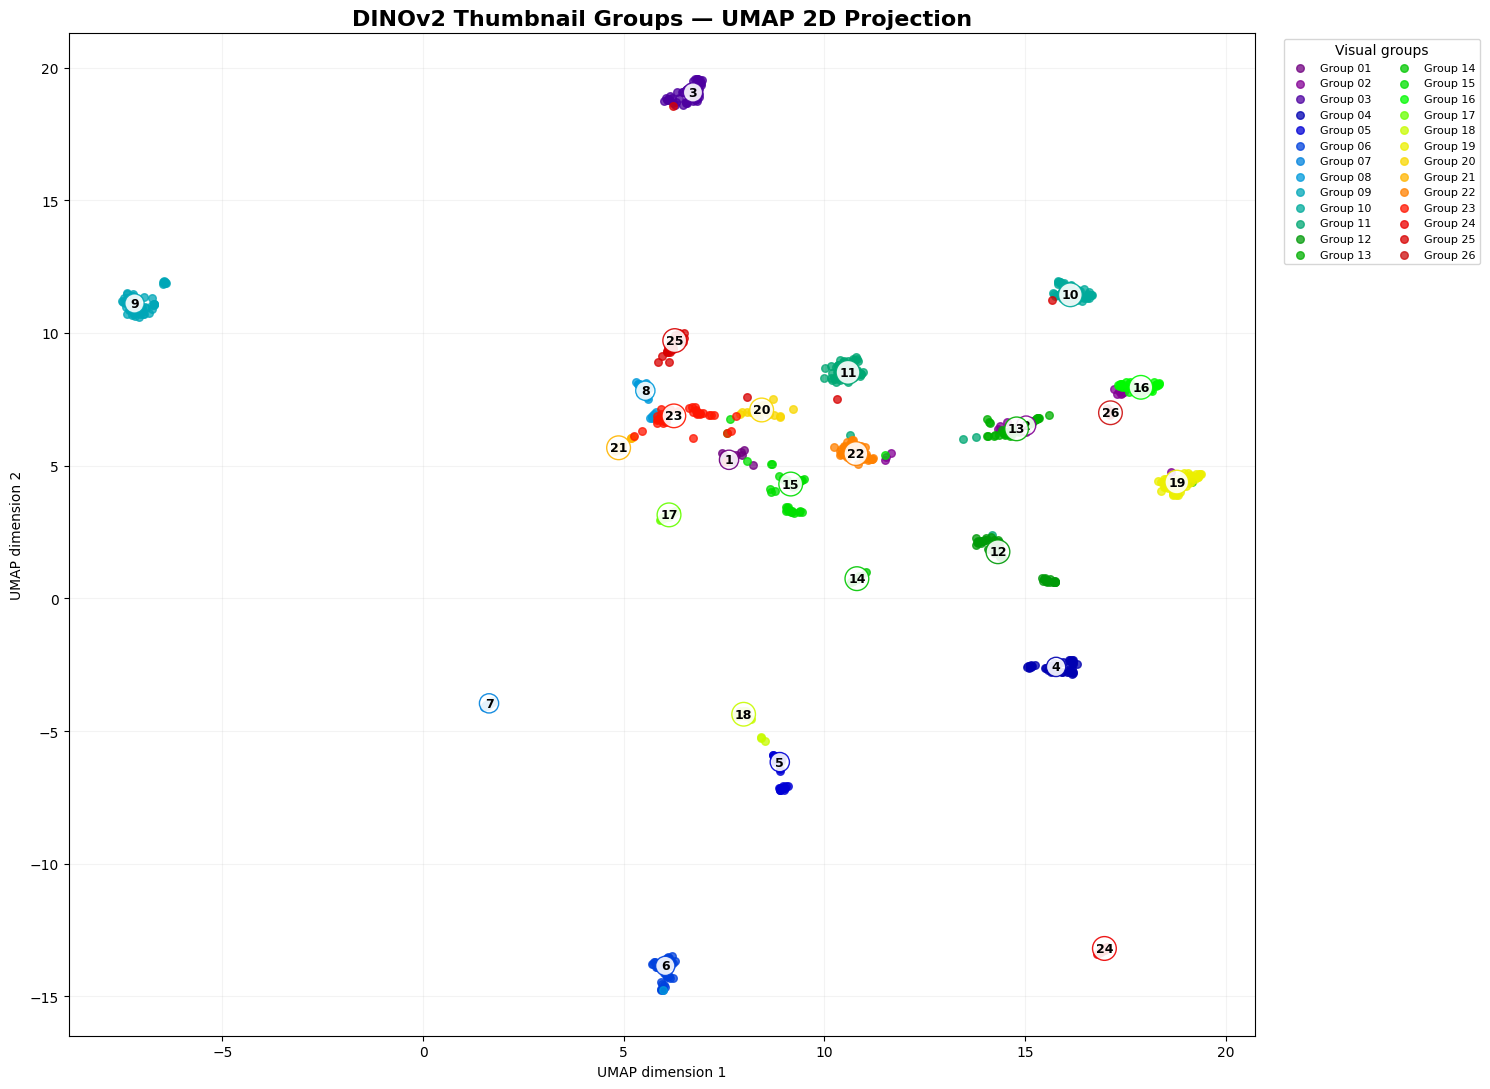

2D cluster plot: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_clusters_2d_umap.png
2D coordinates: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/thumbnail_grouping/thumbnail_clusters_2d_umap.csv


In [ ]:
# ============================================================
# Step 6F: Visualize the 26 clusters in 2D using UMAP
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from umap import UMAP


umap_model = UMAP(
    n_components=2,
    n_neighbors=20,
    min_dist=0.15,
    metric="cosine",
    random_state=42,
)

embedding_2d = umap_model.fit_transform(
    selected_embeddings
)

cluster_plot_data = unique_assignments[
    [
        "canonical_asin",
        "cluster_id",
        "cluster_name",
        "silhouette_value",
    ]
].copy()

cluster_plot_data["umap_x"] = embedding_2d[:, 0]
cluster_plot_data["umap_y"] = embedding_2d[:, 1]


# Create 26 distinct colors
cluster_colors = plt.cm.nipy_spectral(
    np.linspace(0.05, 0.95, FINAL_K)
)

figure, axis = plt.subplots(
    figsize=(15, 11)
)

for cluster_id in range(FINAL_K):
    cluster_points = cluster_plot_data[
        cluster_plot_data["cluster_id"].eq(cluster_id)
    ]

    axis.scatter(
        cluster_points["umap_x"],
        cluster_points["umap_y"],
        s=30,
        alpha=0.75,
        color=cluster_colors[cluster_id],
        label=f"Group {cluster_id + 1:02d}",
    )

    # Put the group number near the middle of its points
    label_x = cluster_points["umap_x"].median()
    label_y = cluster_points["umap_y"].median()

    axis.text(
        label_x,
        label_y,
        str(cluster_id + 1),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        bbox={
            "boxstyle": "circle,pad=0.25",
            "facecolor": "white",
            "edgecolor": cluster_colors[cluster_id],
            "alpha": 0.9,
        },
    )


axis.set_title(
    "DINOv2 Thumbnail Groups — UMAP 2D Projection",
    fontsize=16,
    fontweight="bold",
)

axis.set_xlabel("UMAP dimension 1")
axis.set_ylabel("UMAP dimension 2")

axis.grid(
    alpha=0.15,
)

axis.legend(
    title="Visual groups",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    ncol=2,
)

plt.tight_layout()


UMAP_PLOT_PATH = (
    REPORT_DIR
    / "thumbnail_clusters_2d_umap.png"
)

UMAP_DATA_PATH = (
    REPORT_DIR
    / "thumbnail_clusters_2d_umap.csv"
)

figure.savefig(
    UMAP_PLOT_PATH,
    dpi=300,
    bbox_inches="tight",
)

cluster_plot_data.to_csv(
    UMAP_DATA_PATH,
    index=False,
    encoding="utf-8-sig",
)

plt.show()

print("2D cluster plot:", UMAP_PLOT_PATH)
print("2D coordinates:", UMAP_DATA_PATH)